**DATA TRANSFORMING: Translation of Labels**

In [ ]:
# @title TRANSFORM
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, StandardScaler

vector_df = pd.read_csv('vectordata.csv')

display(vector_df.head())

column_translation = {
    "Centre de santédry": "Health Center",
    "Genre (Gender)": "Gender",
    "Âge (Age)": "Age",
    "Poids (Weight)": "Weight",
    "Circonference du bras (Mua circumference)": "Arm Circumference",
    "Haute température.(temperature, Hyperpyrexia)": "High Temperature",
    "Fièvre depuis 48 heures(Fever 48 hrs)": "Fever 48 Hours",
    "Fièvre au cours des 7 derniers jours (Fever in the last 7 days)": "Fever Last 7 Days",
    "Type de fièvre (Type of Fever)": "Fever Type",
    "Perte de poids (Loss of Weight)": "Weight Loss",
    "Maux de tête (headache)": "Headache",
    "Nausée (Nausea)": "Nausea",
    "Vomissement (Vomiting)": "Vomiting",
    "Douleur articulaire (Joint pain)": "Joint Pain",
    "Gonflement des articulations (Joint Swelling)": "Joint Swelling",
    "Douleur musculaire ( Muscle pain)": "Muscle Pain",
    "Douleur Thoracique (Chaist pain)": "Chest Pain",
    "Mal de dos / Douleur rachidienne ( Back pain / Rachiodynia)": "Back Pain",
    "Troubles de la conscience (Consciousness trouble)": "Consciousness Trouble",
    "Perte d'appétit ou Anorexie (Loss of appetite or Anorexia)": "Loss of appetite or Anorexia",
    "Éruptions cutanées ou Exanthème (Skin rash or Exanthema)": "Skin rash or Exanthema",
    "Éruption morbilliforme (Morbilliform rash)": "Morbilliform rash",
    "Saignement/ Manifestations hémorragiques (Bleeding)": "Bleeding",
    "Rhinorrhée (Rhinorrhea)": "Rhinorrhea",
    "Somnolence ou léthargie (Drowsiness or lethargy)": "Drowsiness or lethargy",
    "Vertige (Dizzy)": "Dizzy",
    "Inflammation de conjonctivite": "Conjunctivitis",
    "Douleur abdominale (stomac pain)": "Stomach pain",
    "Distension abdominale (Ventre gonflé) (Abdominal Distension (Swelling Stomach)/ Ascites)": "Abdominal Distension (Swelling Stomach)/ Ascites)",
    "Mal de gorge (throat pain)" : "throat pain",
    "Toux (Cough)": "Cough",
    "Diarrhée (Diarrhea)": "Diarrhea",
    "Douleur rétro-orbitrale (Retro-orbital pain)": "Retro-orbital pain",
    "Céphalée (Headache)": "Headache",
    "Sensation de frissons ou de froid (Shiver or cold sensation)": "Shiver or cold sensation",
    "Mictions fréquentes.(Frequent Urination)": "Frequent Urination",
    "Mictions fréquentes. (Frequent Urination)": "Frequent Urination",
    "Test TDR": "Rapid Test",
    "Epistaxis ((Bleeding nose)": "Bleeding nose",
    "Goutte épaisse": "Blood smear",
    "Hémoconcentration": "Hemoconcentration",
    "Goût amer dans la gorge (Bitter taste in your Throat)": "Bitter taste in your Throat",
    "Test de garrot positif (Positive tourniquet test)": "Positive tourniquet test",
    "Insuffisance cardiaque ou Myocardite(Heart failure or Myocarditis)": "Heart failure or Myocarditis",
    "Asthme (Astma)": "Asthma",
    "Pâleur cutanéo muqueuse ou Anémie (Mucosal skin pallor or Anemia)": "Pallor or Anemia",
    "Hypoglycémie (Hypoglycemia)": "Hypoglycemia",
    "Paludisme (Malaria)": "Malaria",
    "Drépanocytose": "Sickle Cell Disease",
    "Dengue (Dengua)": "Dengue",
    "Diabète": "Diabetes",
    "Arthrose": "Osteoarthritis",
    "Splénomégalie modérée": "Splenomegaly",
    "Dengue dans le menage (Household Dengue)": "Household Dengue",
    "Maladies diagnostiquées/Dengue": "Diagnosed: Dengue",
    "Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever)": "Diagnosed: Typhoid Fever",
    "Maladies diagnostiquées/Zika": "Diagnosed: Zika",
    "Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases)": "Diagnosed: Other Diseases",
    "Maladies diagnostiquées/Paludisme (Malaria)": "Diagnosed: Malaria",
    "Maladies diagnostiquées/Chikunguya": "Diagnosed: Chikungunya",
    "Maladies diagnostiquées/Fièvre jaune (yellow fever)": "Diagnosed: Yellow Fever",
    "Maladies diagnostiquées/Option 8": "Diagnosed: Other",
    "Autres maladies présentées par le patient": "Other illnesses presented by patient",
    "Maladies diagnostiquées": "Diagnosed"
}

cleaned_column_translation = {}
for key, value in column_translation.items():
    # Apply the cleaning logic to the key
    cleaned_key = ' '.join(key.split())
    cleaned_key = cleaned_key.replace('Ã©', 'e').replace('Ã¨', 'e').replace('Â°C', 'C').replace('Â±', '').replace('.', '').replace('in', '').replace('-', '').replace('secs', '').replace('mmHg', '').replace('SD', '').replace('IQR', '').replace('beats', '').replace('breaths', '').replace('min', '')
    cleaned_key = cleaned_key.replace('  ', ' ') # Remove double spaces

    # Add the cleaned key and the original value to the new dictionary
    cleaned_column_translation[cleaned_key] = value

column_translation = cleaned_column_translation

# Translate columns
vector_df = vector_df.rename(columns=column_translation)

# Remove non-English characters and unnecessary letters from headers
vector_df.columns = vector_df.columns.str.replace(r'[\(\).,]', '', regex=True).str.strip()



display(vector_df.columns)



vector_df.drop(columns=['_uuid', 'Health Center', 'Back Pain',
                         'Other illnesses presented by patient',
                         'Gender', 'Bitter taste in your Throat', 'Asthma', 'Diagnosed: Other'
                         'Prostration', 'Heart failure or Myocarditis', 'Osteoarthritis',
                            'Frequent Urination', 'Cancer', 'Diabète'
                            ], errors='ignore', inplace=True)



print(vector_df.shape)

,Centre de santé,Genre (Gender),Âge (Age),Poids (Weight),Circonference du bras (Mua circumference),"Haute température.(temperature, Hyperpyrexia)",Fièvre depuis 48 heures(Fever 48 hrs),Fièvre au cours des 7 derniers jours (Fever in the last 7 days),Type de fièvre (Type of Fever),Perte de poids (Loss of Weight),...,Maladies diagnostiquées/Paludisme (Malaria),Maladies diagnostiquées/Dengue,Maladies diagnostiquées/Chikunguya,Maladies diagnostiquées/Fièvre jaune (yellow fever),Maladies diagnostiquées/Fièvre Typhoïde (Thyphoid fever),Maladies diagnostiquées/Zika,Maladies diagnostiquées/Autres maladies diagnostiqué (Others diseases),Maladies diagnostiquées/Option 8,Autres maladies présentées par le patient,_uuid
0,CMA de DO,Femme,18,55.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,1,0,0,0,0,0,0,NaN,df22d899-23a3-4c49-8059-6208c130f57d
1,CMA de DO,Homme,26,120.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,1,0,0,0,0,0,0,NaN,4a7ef2f3-4ff0-4215-8cb5-20ba8c8d4355
2,CMA de DO,Homme,25,63.0,NaN,OUI,OUI,OUI,Récurrente,NON,...,1,0,0,0,1,0,0,0,NaN,104f6bc8-f39a-482b-b680-7ac1f8cccc86
3,CMA de DO,Homme,3,12.0,"13,5",OUI,OUI,NON,Récurrente,NON,...,1,0,0,0,0,0,0,0,NaN,26d7d04a-1a1c-4d4b-b64a-606f968e6d9c
4,CMA de DO,Homme,8,24.0,NaN,OUI,OUI,NON,Récurrente,NON,...,1,0,0,0,0,0,0,0,NaN,eb694f52-51ff-488d-9beb-2923a572a4cf


Index(['Centre de santé', 'Gender', 'Age', 'Weight', 'Arm Circumference',
       'Haute températuretemperature Hyperpyrexia', 'Fever 48 Hours',
       'Fièvre au cours des 7 derniers jours Fever in the last 7 days',
       'Fever Type', 'Weight Loss',
       ...
       'Diagnosed: Malaria', 'Diagnosed: Dengue', 'Diagnosed: Chikungunya',
       'Diagnosed: Yellow Fever', 'Diagnosed: Typhoid Fever',
       'Diagnosed: Zika', 'Diagnosed: Other Diseases', 'Diagnosed: Other',
       'Other illnesses presented by patient', '_uuid'],
      dtype='object', length=109)

(299, 102)


**DATA CLEANING: Removing Unnecessary Features**

In [ ]:
# @title CLEAN
# Calculate null percentages before dropping columns
null_percentages = vector_df.isnull().sum()/vector_df.shape[0]*100
null_percentages = null_percentages.sort_values(ascending=False)



display(null_percentages)



# Show null percentages higher than 30%
print("Null percentages higher than 30%:")
display(null_percentages[null_percentages > 30])



vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
vector_df.replace({'Oui': 1, 'Non': 0}, inplace=True)
vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
vector_df.replace({'Positif': 1, 'Négatif': 0}, inplace=True)

# Replace comma with period in all columns, including 'Pulse rate (mean per minute ± SD)'
vector_df = vector_df.replace(',', '.', regex=True, inplace=False)

display(vector_df)



vector_df.drop(columns=['Arm Circumference',
                        'Temps de remplissage capillaire (médiane secs IQR). / Capillary refill time (median secs IQR)',
                        'Pression artérielle (moyenne mmHg ± SD). / Arterial blood pressure (mean mmHg ± SD)'], errors='ignore', inplace=True)

print(vector_df.shape)



# Removes noise in age column
vector_df = vector_df[~vector_df['Age'].isin(['15-Dec', '07-Dec'])]
display(vector_df.shape)



#The removed download portion of the translated_vector_data.csv

,0
Arm Circumference,91.638796
Temps de remplissage capillaire médiane secs IQR / Capillary refill time median secs IQR,69.565217
Pression artérielle moyenne mmHg ± SD / Arterial blood pressure mean mmHg ± SD,56.856187
Lymphocytes,50.836120
Hematocrite Hematrocrit,34.782609
...,...
Diagnosed: Yellow Fever,0.000000
Diagnosed: Typhoid Fever,0.000000
Diagnosed: Zika,0.000000
Diagnosed: Other Diseases,0.000000


Null percentages higher than 30%:


,0
Arm Circumference,91.638796
Temps de remplissage capillaire médiane secs IQR / Capillary refill time median secs IQR,69.565217
Pression artérielle moyenne mmHg ± SD / Arterial blood pressure mean mmHg ± SD,56.856187
Lymphocytes,50.836120
Hematocrite Hematrocrit,34.782609
Weight,34.448161


/tmp/ipython-input-2-4131796669.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'OUI': 1, 'NON': 0}, inplace=True)
/tmp/ipython-input-2-4131796669.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  vector_df.replace({'Récurrente': 1, 'Intermittente': 0}, inplace=True)
/tmp/ipython-input-2-4131796669.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the f

,Centre de santé,Age,Weight,Arm Circumference,Haute températuretemperature Hyperpyrexia,Fever 48 Hours,Fièvre au cours des 7 derniers jours Fever in the last 7 days,Fever Type,Weight Loss,Headache,...,Dengue,Diagnosed,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Diagnosed: Other
0,CMA de DO,18,55.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,NaN,Paludisme (Malaria) Dengue,1,1,0,0,0,0,0,0
1,CMA de DO,26,120.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,1.0,Paludisme (Malaria) Dengue,1,1,0,0,0,0,0,0
2,CMA de DO,25,63.0,NaN,1,1.0,1.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria) Fièvre Typhoïde (Thyphoid ...,1,0,0,0,1,0,0,0
3,CMA de DO,3,12.0,13.5,1,1.0,0.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
4,CMA de DO,8,24.0,NaN,1,1.0,0.0,1.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,CMA de DAFRA,9,21.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria) Fièvre jaune (yellow fever),1,0,0,1,0,0,0,0
295,CMA de DAFRA,6,19.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
296,CMA de DAFRA,9,NaN,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0
297,CMA de DAFRA,7,16.0,NaN,1,1.0,0.0,0.0,0.0,1.0,...,0.0,Paludisme (Malaria),1,0,0,0,0,0,0,0


(299, 101)


(297, 101)

The translated dataset has been saved as `translated_vector_data.csv`. You can download it from the files panel in the left sidebar.

**DATA IMPUTATION**

,Age,Weight,High Temperature,Fever 48 Hours,Fever Last 7 Days,Fever Type,Weight Loss,Headache,Nausea,Vomiting,...,Household Dengue,Dengue,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed Diseases,Diagnosed: Other Diseases
0,18.0,55.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,Paludisme (Malaria) Dengue,0
1,26.0,120.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,Paludisme (Malaria) Dengue,0
2,25.0,63.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,Paludisme (Malaria) Fièvre Typhoïde (Thyphoid ...,0
3,3.0,12.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Paludisme (Malaria),0
4,8.0,24.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Paludisme (Malaria),0


/tmp/ipython-input-3-3777846963.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-3-3777846963.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-3-3777846963.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=vector_df, x=col, palette="Set2")
/tmp/ipython-input-3-3777846963.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable t

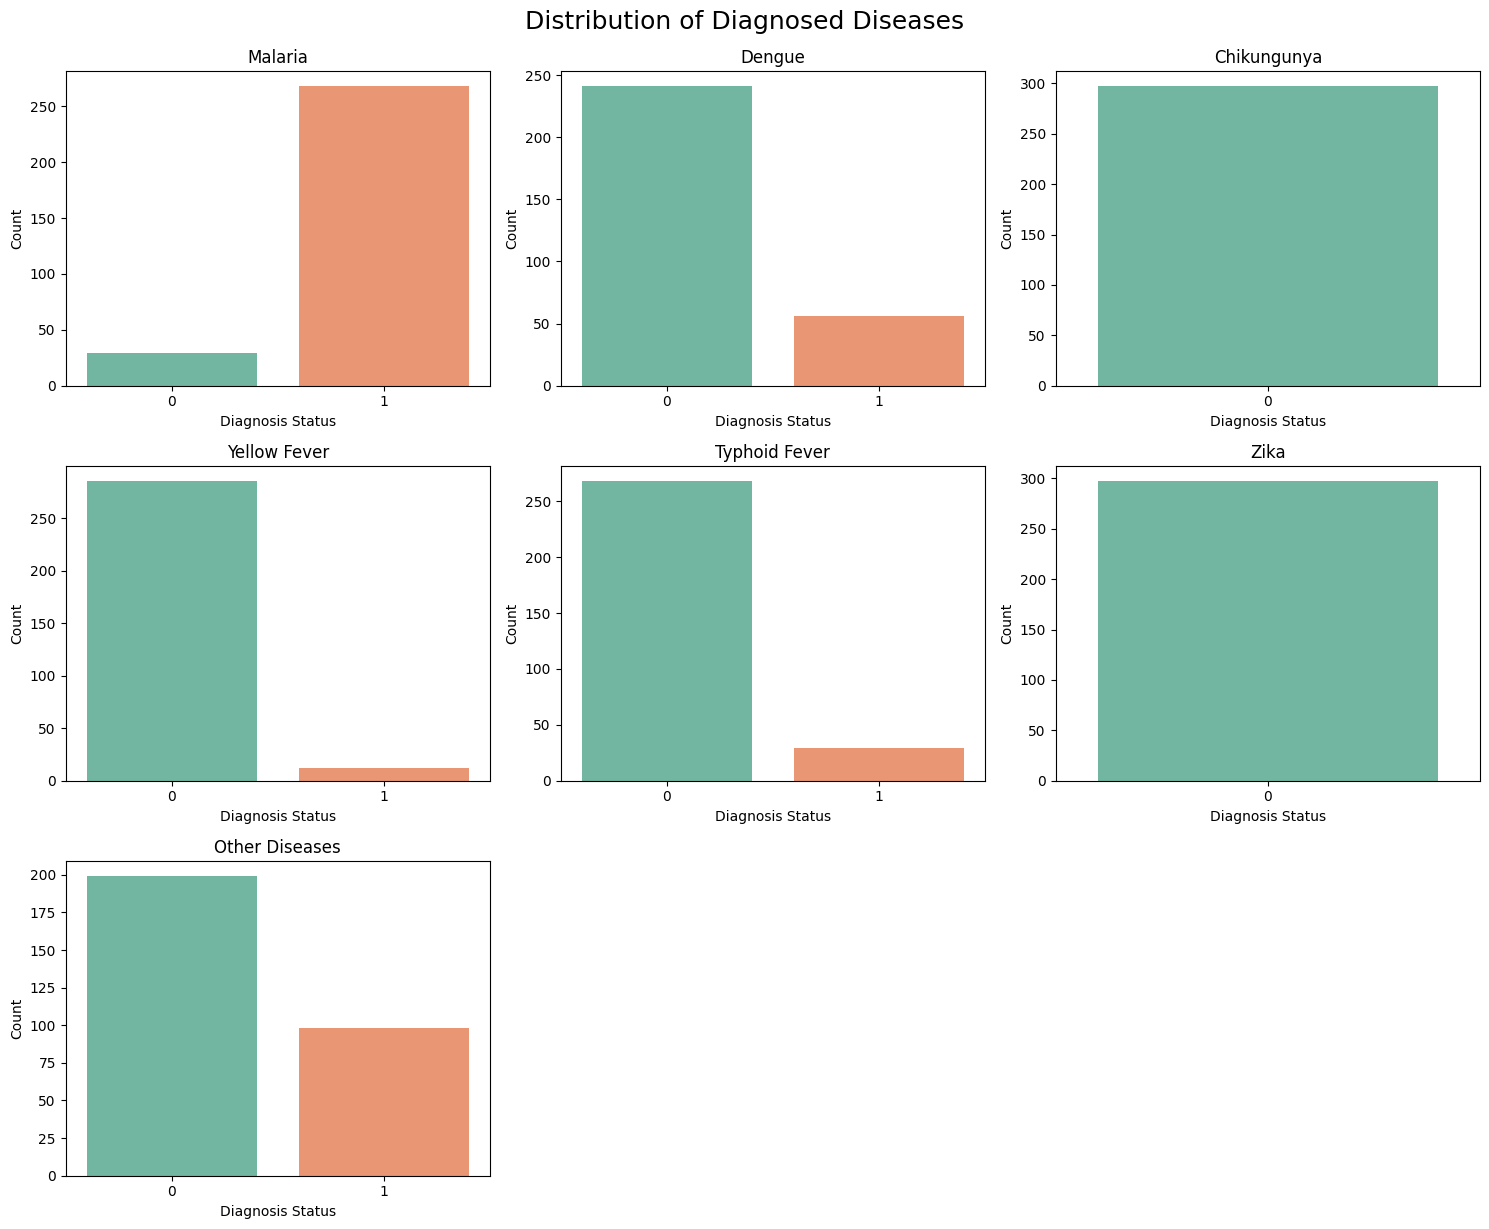

,count
Diagnosed Diseases,
Malaria,118
"Malaria, Other Diseases",74
"Malaria, Dengue",36
"Malaria, Typhoid Fever",24
Other Diseases,14
Dengue,8
Yellow Fever,8
"Malaria, Dengue, Other Diseases",4
"Other Disease, Dengue",3


Missing values after imputation for specified columns:


,0
Age,0
Respiratory rate (median breaths/min IQR),0
Pulse rate (mean beats/min ± SD),0
Fever 48 Hours,0
Fever Last 7 Days,0
High Temperature,0
Fever Type,0
Retro-orbital pain,0
Headache,0
Muscle Pain,0


,Age,Weight,Fever Type,Weight Loss,Headache,Nausea,Vomiting,Joint Pain,Joint Swelling,Muscle Pain,...,Dengue,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed Diseases,Diagnosed: Other Diseases,Fever_Level
0,18,55.0,1,0.0,1,1.0,0,1,0,1,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,"Malaria, Dengue",0,Severe
1,26,120.0,1,0.0,1,1.0,1,1,0,1,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,"Malaria, Dengue",0,Severe
2,25,63.0,1,0.0,1,0.0,1,1,0,1,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,"Malaria, Typhoid Fever",0,Severe
3,3,12.0,1,0.0,1,0.0,1,0,0,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Malaria,0,Moderate
4,8,24.0,1,0.0,1,0.0,1,0,0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Malaria,0,Moderate


Shape of the DataFrame after removing columns:


(298, 32)

,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Household Dengue,Sickle Cell Disease,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases
0,18,Severe,26,131,0,1,1,1,0,0,...,0,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
1,26,Severe,28,38,0,1,1,1,0,1,...,1,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
2,25,Severe,22,100,0,1,1,1,0,1,...,0,0,"Malaria, Typhoid Fever",1.0,0.0,0.0,0.0,1.0,0.0,0
3,3,Moderate,26,88,0,1,0,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0
4,8,Moderate,32,109,0,1,1,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0


,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Household Dengue,Sickle Cell Disease,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases
0,18,Severe,26,131,0,1,1,1,0,0,...,0,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
1,26,Severe,28,38,0,1,1,1,0,1,...,1,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
2,25,Severe,22,100,0,1,1,1,0,1,...,0,0,"Malaria, Typhoid Fever",1.0,0.0,0.0,0.0,1.0,0.0,0
3,3,Moderate,26,88,0,1,0,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0
4,8,Moderate,32,109,0,1,1,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0


In [ ]:
# @title FINALIZATION

try:
    translated_df = pd.read_csv('translated_vector_data_1.csv', encoding='utf-8')
except UnicodeDecodeError:
    try:
        translated_df = pd.read_csv('translated_vector_data_1.csv', encoding='latin-1')
    except UnicodeDecodeError:
        translated_df = pd.read_csv('translated_vector_data_1.csv', encoding='cp1252')



display(translated_df.head())



# Identify diagnosis columns
diagnosed_cols = [col for col in translated_df.columns if col.startswith('Diagnosed:')]




# Set up the subplot grid (adjust columns/rows as needed)
n_cols = 3
n_rows = (len(diagnosed_cols) + n_cols - 1) // n_cols
plt.figure(figsize=(5 * n_cols, 4 * n_rows))




# Loop and plot each column
for i, col in enumerate(diagnosed_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(data=vector_df, x=col, palette="Set2")
    plt.title(col.replace("Diagnosed:", "").strip())
    plt.xlabel('Diagnosis Status')
    plt.ylabel('Count')

plt.tight_layout()
plt.suptitle('Distribution of Diagnosed Diseases', fontsize=18, y=1.02)
plt.show()




#trans part
diagnosis_eng = {
    'Paludisme (Malaria) Dengue': 'Malaria, Dengue',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Typhoid Fever',
    'Paludisme (Malaria)': 'Malaria',
    'Paludisme (Malaria) Chikunguya': 'Chikungunya',
    'Paludisme (Malaria) Fièvre jaune (yellow fever)': 'Yellow Fever',
    'Paludisme (Malaria) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Option 8': 'Malaria, Other Diseases',
    'Paludisme (Malaria) Dengue Autres maladies diagnostiqué (Others diseases)': 'Malaria, Dengue, Other Diseases',
    'Paludisme (Malaria) Fièvre Typhoïde (Thyphoid fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Typhoid Fever, Other Diseases',
    'Paludisme (Malaria) Chikunguya Autres maladies diagnostiqué (Others diseases)': 'Malaria, Chikungunya, Other Diseases',
    'Dengue Autres maladies diagnostiqué (Others diseases)': 'Other Disease, Dengue',
    'Dengue Fièvre jaune (yellow fever)': 'Dengue, Yellow Fever',
    'Paludisme (Malaria) Fièvre jaune (yellow fever) Autres maladies diagnostiqué (Others diseases)': 'Malaria, Yellow Fever, Other Diseases',
    'Fièvre Typhoïde (Thyphoid fever)': 'Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre Typhoïde (Thyphoid fever)': 'Malaria, Dengue, Typhoid Fever',
    'Fièvre jaune (yellow fever) Fièvre Typhoïde (Thyphoid fever)': 'Yellow Fever, Typhoid Fever',
    'Paludisme (Malaria) Dengue Fièvre jaune (yellow fever)': 'Malaria, Dengue, Yellow Fever',
    'Dengue Fièvre Typhoïde (Thyphoid fever)': 'Dengue, Typhoid Fever',
    'Autres maladies diagnostiqué (Others diseases)': 'Other Diseases',
    '(Malaria) Dengue': 'Malaria, Dengue'

}

translated_df['Diagnosed Diseases'] = translated_df['Diagnosed Diseases'].replace(diagnosis_eng)

display(translated_df['Diagnosed Diseases'].value_counts())



# Define the columns to impute based on the user's list and available columns
columns_to_impute = [
    'Age',
    'Respiratory rate (median breaths/min IQR)',
    'Pulse rate (mean beats/min ± SD)',
    'Fever 48 Hours',
    'Fever Last 7 Days',
    'High Temperature',  # Add 'High Temperature' to the list for imputation
    'Fever Type',
    'Retro-orbital pain',
    'Headache',
    'Muscle Pain',
    'Joint Pain',
    'Joint Swelling',
    'Vomiting',
    'Abdominal Distension',
    'Stomach pain',
    'Bleeding',
    'Bleeding nose',
    'Skin rash or Exanthema',
    'Morbilliform rash',
    'Positive tourniquet test',
    'Drowsiness or lethargy',
    'Shiver or cold sensation',
    'Profuse sweating',
    'Respiratory distress',
    'Cough',
    'Household Dengue',
    'Sickle Cell Disease'
]



# Impute missing values
for col in columns_to_impute:
    if col in translated_df.columns:
        # Check data type to decide between median and mode
        if translated_df[col].dtype in ['int64', 'float64']:
            # Impute with median for numerical columns
            median_value = translated_df[col].median()
            translated_df[col] = translated_df[col].fillna(median_value)
            # Convert to integer type
            translated_df[col] = translated_df[col].astype(int)
        else:
            # Impute with mode for categorical/object columns
            mode_value = translated_df[col].mode()[0]
            translated_df[col] = translated_df[col].fillna(mode_value)
    else:
        print(f"Warning: Column '{col}' not found in the DataFrame.")




# Display the number of missing values after imputation for the specified columns
print("Missing values after imputation for specified columns:")
display(translated_df[columns_to_impute].isnull().sum())



# Fever Binning
def fever_level(row):
    # Handle potential NaN values by converting to 0 before converting to int
    fever_48 = int(row.get('Fever 48 Hours', 0) or 0)
    fever_7d = int(row.get('Fever Last 7 Days', 0) or 0)
    temp = int(row.get('High Temperature', 0) or 0)
    score = fever_48 + fever_7d + temp
    if score == 0: return 'None'
    elif score == 1: return 'Mild'
    elif score == 2: return 'Moderate'
    else: return 'Severe'

translated_df['Fever_Level'] = translated_df.apply(fever_level, axis=1)
translated_df.drop(columns=[
    'Fever 48 Hours', # Update to translated column name
    'Fever Last 7 Days', # Update to translated column name
    'High Temperature' # Update to translated column name
], inplace=True)

display(translated_df.head())



# Define the columns to keep
columns_to_keep = [
    'Age',
    'Fever_Level',
    'Respiratory rate (median breaths/min IQR)',
    'Pulse rate (mean beats/min ± SD)',
    'Retro-orbital pain',
    'Headache',
    'Muscle Pain',
    'Joint Pain',
    'Joint Swelling',
    'Vomiting',
    'Abdominal Distension',
    'Stomach pain',
    'Bleeding',
    'Bleeding nose',
    'Skin rash or Exanthema',
    'Morbilliform rash',
    'Positive tourniquet test',
    'Drowsiness or lethargy',
    'Shiver or cold sensation',
    'Profuse sweating',
    'Respiratory distress',
    'Cough',
    'Household Dengue',
    'Sickle Cell Disease',
    'Diagnosed Diseases',
    'Diagnosed: Malaria',
    'Diagnosed: Dengue',
    'Diagnosed: Chikungunya',
    'Diagnosed: Yellow Fever',
    'Diagnosed: Typhoid Fever',
    'Diagnosed: Zika',
    'Diagnosed: Other Diseases'
]




# Create a new DataFrame with only the specified columns
translated_df = translated_df[columns_to_keep]




# Display the shape of the new DataFrame
print("Shape of the DataFrame after removing columns:")
display(translated_df.shape)

# Display the first few rows of the new DataFrame
display(translated_df.head())

translated_df.to_csv('processed_translated_data.csv', index=False)

df_processed = pd.read_csv('processed_translated_data.csv')

display(df_processed.head())

##SVM MODEL

**Machine Learning Model: Suppot Vector Machines**


### 1. Load the processed data

In [ ]:
import pandas as pd

# Load the processed data
df = pd.read_csv('processed_translated_data.csv')

# Display the first few rows and the shape of the DataFrame
display(df.head())
print(df.shape)

,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Household Dengue,Sickle Cell Disease,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases
0,18,Severe,26,131,0,1,1,1,0,0,...,0,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
1,26,Severe,28,38,0,1,1,1,0,1,...,1,0,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0
2,25,Severe,22,100,0,1,1,1,0,1,...,0,0,"Malaria, Typhoid Fever",1.0,0.0,0.0,0.0,1.0,0.0,0
3,3,Moderate,26,88,0,1,0,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0
4,8,Moderate,32,109,0,1,1,0,0,1,...,0,0,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0


(298, 32)


### 2. Prepare data for initial SVM (Binary Classification)

In [ ]:
# Drop the 'Diagnosed Diseases' column as it contains multiple labels

# Define features (X) and target (y) for binary classification
X = df.drop(columns=['Diagnosed Diseases', 'Diagnosed: Malaria', 'Diagnosed: Dengue',
                     'Diagnosed: Chikungunya', 'Diagnosed: Yellow Fever',
                     'Diagnosed: Typhoid Fever', 'Diagnosed: Zika', 'Diagnosed: Other Diseases'])

# Create a binary target variable: 1 if any of the diagnosed disease columns is 1, 0 otherwise
df['Has_Vector_Borne_Disease'] = df[['Diagnosed: Malaria', 'Diagnosed: Dengue',
                                     'Diagnosed: Chikungunya', 'Diagnosed: Yellow Fever',
                                     'Diagnosed: Typhoid Fever', 'Diagnosed: Zika',
                                     'Diagnosed: Other Diseases']].max(axis=1)

y = df['Has_Vector_Borne_Disease']

# Display the first few rows of X and y
display(X.head())
display(y.head())

,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Skin rash or Exanthema,Morbilliform rash,Positive tourniquet test,Drowsiness or lethargy,Shiver or cold sensation,Profuse sweating,Respiratory distress,Cough,Household Dengue,Sickle Cell Disease
0,18,Severe,26,131,0,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,26,Severe,28,38,0,1,1,1,0,1,...,0,0,0,0,0,0,0,0,1,0
2,25,Severe,22,100,0,1,1,1,0,1,...,0,0,0,0,1,0,1,0,0,0
3,3,Moderate,26,88,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,8,Moderate,32,109,0,1,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0


,Has_Vector_Borne_Disease
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


### 3. Split data

In [ ]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (238, 24)
Shape of X_test: (60, 24)
Shape of y_train: (238,)
Shape of y_test: (60,)


### 4. Scale features

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Identify non-numeric columns in X_train because StandardScaler gumagana lang siya sa numerical values
non_numeric_cols = X_train.select_dtypes(include=['object', 'category']).columns

# Handle non-numeric columns before scaling
# For example, one-hot encode or drop them
# Here, we'll one-hot encode for demonstration
X_train = pd.get_dummies(X_train, columns=non_numeric_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=non_numeric_cols, drop_first=True)

# Align columns after one-hot encoding - crucial for consistent scaling
train_cols = X_train.columns
test_cols = X_test.columns

missing_in_test = set(train_cols) - set(test_cols)
for c in missing_in_test:
    X_test[c] = 0

missing_in_train = set(test_cols) - set(train_cols)
for c in missing_in_train:
    X_train[c] = 0

# Ensure the order of columns is the same
X_test = X_test[train_cols]


# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler on the training data and transform both training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames for easier handling
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

# Display the first few rows of the scaled data -- mean of 0 and a standard deviation of 1
display(X_train_scaled_df.head())

,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Positive tourniquet test,Drowsiness or lethargy,Shiver or cold sensation,Profuse sweating,Respiratory distress,Cough,Household Dengue,Sickle Cell Disease,Fever_Level_Moderate,Fever_Level_Severe
0,-0.579306,0.371701,-0.479381,-0.160817,0.535244,-1.125463,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
1,-0.347428,0.371701,-1.687462,-0.160817,0.535244,0.888523,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
2,-1.043063,-0.592493,1.403805,-0.160817,0.535244,-1.125463,-0.911465,-0.092057,-1.164661,-0.186501,...,1.533660,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
3,0.487334,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,0.858619,-0.186501,...,-0.652035,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
4,1.646726,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,-1.164661,-0.186501,...,-0.652035,1.703420,-1.106480,0.0,2.633122,-0.469588,-0.064957,-0.14649,0.658586,-0.3725


### 5. Train and evaluate initial SVM model (Binary Classification)

Initial SVM Model Performance (Binary Classification):
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00         2
         1.0       0.97      1.00      0.98        58

    accuracy                           0.97        60
   macro avg       0.48      0.50      0.49        60
weighted avg       0.93      0.97      0.95        60



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


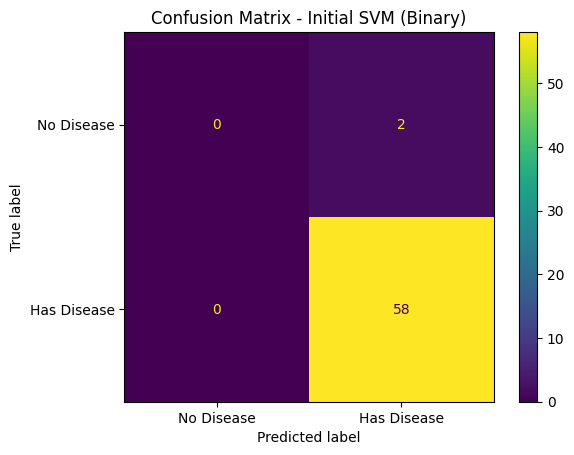

Overall Accuracy: 0.9667
Training Accuracy (Initial Binary SVM): 0.9874


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix

# Initialize the SVM classifier
svm_model_initial = SVC(random_state=42)

# Train the model
svm_model_initial.fit(X_train_scaled_df, y_train)

# Make predictions on the scaled testing data
y_pred_initial = svm_model_initial.predict(X_test_scaled_df)

# Evaluate the model
print("Initial SVM Model Performance (Binary Classification):")
print(classification_report(y_test, y_pred_initial))

# Display the confusion matrix
cm_initial = confusion_matrix(y_test, y_pred_initial)
disp_initial = ConfusionMatrixDisplay(confusion_matrix=cm_initial, display_labels=['No Disease', 'Has Disease'])
disp_initial.plot()
plt.title('Confusion Matrix - Initial SVM (Binary)')
plt.show()

# Calculate and display overall accuracy
accuracy_initial = accuracy_score(y_test, y_pred_initial)
print(f"Overall Accuracy: {accuracy_initial:.4f}")

# Show training value
# Calculate and display training accuracy
y_train_pred_initial = svm_model_initial.predict(X_train_scaled_df)
training_accuracy_initial = accuracy_score(y_train, y_train_pred_initial)
print(f"Training Accuracy (Initial Binary SVM): {training_accuracy_initial:.4f}")

In [ ]:
# Display the training and testing accuracy of the initial binary SVM model
print(f"Training Accuracy (Initial Binary SVM): {training_accuracy_initial:.4f}")
print(f"Testing Accuracy (Initial Binary SVM): {accuracy_initial:.4f}")

Training Accuracy (Initial Binary SVM): 0.9874
Testing Accuracy (Initial Binary SVM): 0.9667


### 6. Tune SVM hyperparameters

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for GridSearchCV
param_grid = {'C': [0.01, 0.1, 1, 10, 100],
              'gamma': ['scale', 'auto'],
              'kernel': ['linear', 'rbf']}

# Initialize GridSearchCV -- WHY GridSearch?
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy')

# Fit GridSearchCV on the scaled training data
grid_search.fit(X_train_scaled_df, y_train)

# Get the best hyperparameters
best_params = grid_search.best_params_

print("Best hyperparameters found:", best_params)

Best hyperparameters found: {'C': 0.01, 'gamma': 'scale', 'kernel': 'linear'}


### 7. Evaluate tuned SVM model

Tuned SVM Model Performance (Binary Classification):
              precision    recall  f1-score   support

         0.0       0.00      0.00      0.00         2
         1.0       0.97      1.00      0.98        58

    accuracy                           0.97        60
   macro avg       0.48      0.50      0.49        60
weighted avg       0.93      0.97      0.95        60



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


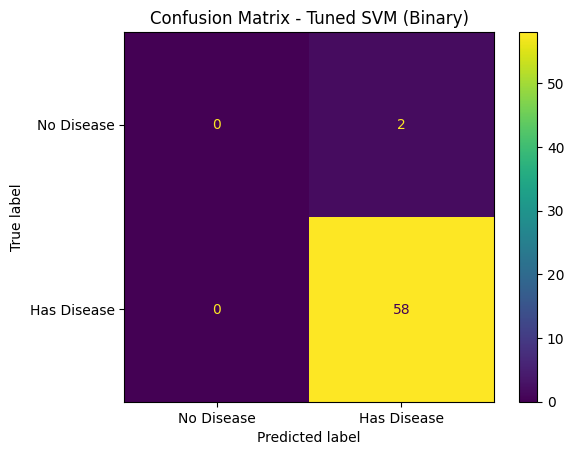

Overall Accuracy: 0.9667


In [ ]:
# Initialize the SVM classifier with the best hyperparameters
svm_model_tuned = SVC(C=best_params['C'], gamma=best_params['gamma'], kernel=best_params['kernel'], random_state=42)

# Train the tuned model
svm_model_tuned.fit(X_train_scaled_df, y_train)

# Make predictions on the scaled testing data
y_pred_tuned = svm_model_tuned.predict(X_test_scaled_df)

# Evaluate the tuned model
print("Tuned SVM Model Performance (Binary Classification):")
print(classification_report(y_test, y_pred_tuned))

# Display the confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
disp_tuned = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=['No Disease', 'Has Disease'])
disp_tuned.plot()
plt.title('Confusion Matrix - Tuned SVM (Binary)')
plt.show()

# Calculate and display overall accuracy
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Overall Accuracy: {accuracy_tuned:.4f}")

#training value again
# nothing change -- becasue imabalnce

In [ ]:
# Calculate and display training accuracy for tuned binary SVM
y_train_pred_tuned = svm_model_tuned.predict(X_train_scaled_df)
training_accuracy_tuned = accuracy_score(y_train, y_train_pred_tuned)
print(f"Training Accuracy (Tuned Binary SVM): {training_accuracy_tuned:.4f}")

# Display testing accuracy for tuned binary SVM (already calculated as accuracy_tuned)
print(f"Testing Accuracy (Tuned Binary SVM): {accuracy_tuned:.4f}")

Training Accuracy (Tuned Binary SVM): 0.9832
Testing Accuracy (Tuned Binary SVM): 0.9667


### 8. Prepare data for multi-label SVM

In [ ]:
# Define features (X) and multiple target variables (y) for multi-label classification
# Use the scaled features from the binary classification step as the features for multi-label classification as well.
X_multi = X_train_scaled_df.copy()
X_test_multi = X_test_scaled_df.copy()

# Select the diagnosis columns as target variables
y_multi = df[['Diagnosed: Malaria', 'Diagnosed: Dengue',
              'Diagnosed: Chikungunya', 'Diagnosed: Yellow Fever',
              'Diagnosed: Typhoid Fever', 'Diagnosed: Zika',
              'Diagnosed: Other Diseases']]

# Display the first few rows of X_multi and y_multi
display(X_multi.head())
display(y_multi.head())

,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Positive tourniquet test,Drowsiness or lethargy,Shiver or cold sensation,Profuse sweating,Respiratory distress,Cough,Household Dengue,Sickle Cell Disease,Fever_Level_Moderate,Fever_Level_Severe
0,-0.579306,0.371701,-0.479381,-0.160817,0.535244,-1.125463,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
1,-0.347428,0.371701,-1.687462,-0.160817,0.535244,0.888523,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
2,-1.043063,-0.592493,1.403805,-0.160817,0.535244,-1.125463,-0.911465,-0.092057,-1.164661,-0.186501,...,1.533660,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
3,0.487334,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,0.858619,-0.186501,...,-0.652035,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
4,1.646726,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,-1.164661,-0.186501,...,-0.652035,1.703420,-1.106480,0.0,2.633122,-0.469588,-0.064957,-0.14649,0.658586,-0.3725


,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases
0,1.0,1.0,0.0,0.0,0.0,0.0,0
1,1.0,1.0,0.0,0.0,0.0,0.0,0
2,1.0,0.0,0.0,0.0,1.0,0.0,0
3,1.0,0.0,0.0,0.0,0.0,0.0,0
4,1.0,0.0,0.0,0.0,0.0,0.0,0


### 9. Split data for multi-label SVM

In [ ]:
# We will use the same split as the binary classification for consistency
# The X_train_multi and X_test_multi are already defined in the previous step.
# Now, split the multi-label target variable y_multi

# Ensure the indices of y_multi match the original dataframe before splitting
y_multi_aligned = y_multi.loc[df.index]

y_train_multi, y_test_multi = train_test_split(y_multi_aligned, test_size=0.2, random_state=42, stratify=df['Has_Vector_Borne_Disease'])

print("Shape of y_train_multi:", y_train_multi.shape)
print("Shape of y_test_multi:", y_test_multi.shape)

Shape of y_train_multi: (238, 7)
Shape of y_test_multi: (60, 7)


### 10. Scale features for multi-label SVM

In [ ]:
# The features (X_train_multi and X_test_multi) are already scaled from the binary classification step.
# We will use these scaled features directly for the multi-label classification.

# Display the first few rows of the scaled multi-label features to confirm
print("Scaled features for multi-label SVM:")
display(X_train_scaled_df.head())
display(X_test_scaled_df.head())

Scaled features for multi-label SVM:


,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Positive tourniquet test,Drowsiness or lethargy,Shiver or cold sensation,Profuse sweating,Respiratory distress,Cough,Household Dengue,Sickle Cell Disease,Fever_Level_Moderate,Fever_Level_Severe
0,-0.579306,0.371701,-0.479381,-0.160817,0.535244,-1.125463,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
1,-0.347428,0.371701,-1.687462,-0.160817,0.535244,0.888523,1.097134,-0.092057,0.858619,-0.186501,...,-0.652035,1.703420,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
2,-1.043063,-0.592493,1.403805,-0.160817,0.535244,-1.125463,-0.911465,-0.092057,-1.164661,-0.186501,...,1.533660,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
3,0.487334,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,0.858619,-0.186501,...,-0.652035,-0.587054,0.903767,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.3725
4,1.646726,-0.592493,0.266787,-0.160817,0.535244,0.888523,-0.911465,-0.092057,-1.164661,-0.186501,...,-0.652035,1.703420,-1.106480,0.0,2.633122,-0.469588,-0.064957,-0.14649,0.658586,-0.3725


,Age,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,Abdominal Distension,...,Positive tourniquet test,Drowsiness or lethargy,Shiver or cold sensation,Profuse sweating,Respiratory distress,Cough,Household Dengue,Sickle Cell Disease,Fever_Level_Moderate,Fever_Level_Severe
0,-0.301052,-0.110396,-0.088531,-0.160817,0.535244,-1.125463,-0.911465,-0.092057,0.858619,-0.186501,...,-0.652035,-0.587054,-1.106480,0.0,-0.379777,-0.469588,-0.064957,-0.14649,-1.518406,-0.372500
1,-0.069174,-0.110396,1.332741,-0.160817,0.535244,-1.125463,-0.911465,-0.092057,0.858619,-0.186501,...,-0.652035,-0.587054,-1.106480,0.0,-0.379777,-0.469588,-0.064957,-0.14649,-1.518406,2.684566
2,-0.718433,-0.351445,0.160192,-0.160817,0.535244,0.888523,1.097134,-0.092057,-1.164661,-0.186501,...,1.533660,1.703420,-1.106480,0.0,-0.379777,-0.469588,-0.064957,-0.14649,0.658586,-0.372500
3,2.110483,-0.110396,-0.514913,-0.160817,-1.868306,-1.125463,-0.911465,-0.092057,-1.164661,-0.186501,...,-0.652035,-0.587054,-1.106480,0.0,-0.379777,-0.469588,-0.064957,-0.14649,-1.518406,-0.372500
4,1.507599,-0.110396,-0.514913,6.218253,0.535244,0.888523,1.097134,-0.092057,-1.164661,-0.186501,...,-0.652035,-0.587054,0.903767,0.0,2.633122,-0.469588,-0.064957,-0.14649,0.658586,-0.372500


### 11. Train and evaluate initial multi-label SVM model

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.metrics import hamming_loss, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Initialize the OneVsRestClassifier with a linear SVM -- purpose and determine the difference between this and the grid search
ovr_svm_initial = OneVsRestClassifier(SVC(kernel='linear', random_state=42))

# Impute missing values in y_train_multi with 0
y_train_multi_filled = y_train_multi.fillna(0)

# Train the model
ovr_svm_initial.fit(X_train_scaled_df, y_train_multi_filled)

# Make predictions on the scaled testing data
y_pred_multi_initial = ovr_svm_initial.predict(X_test_scaled_df)

# Evaluate the model using multi-label metrics

# Ensure y_test_multi and y_pred_multi_initial have the same shape and handle potential NaNs
# Fill NaN values in y_test_multi with 0 for evaluation
# -- This line ensures that any potential NaN values in the predictions are replaced with 0 before evaluation.
y_test_multi_filled = y_test_multi.fillna(0)
y_pred_multi_initial_filled = np.nan_to_num(y_pred_multi_initial, nan=0)


# Exact Match Ratio
# -- Calculates the proportion of instances where the predicted set of labels exactly matches the true set of labels.
exact_match_ratio = np.all(y_test_multi_filled == y_pred_multi_initial_filled, axis=1).mean()
print(f"Exact Match Ratio (Initial Multi-label SVM): {exact_match_ratio:.4f}")

# Hamming Loss
# -- Calculates the average number of incorrect labels per instance. A lower Hamming loss indicates better performance.
hamming_loss_initial = hamming_loss(y_test_multi_filled, y_pred_multi_initial_filled)
print(f"Hamming Loss (Initial Multi-label SVM): {hamming_loss_initial:.4f}")

# Accuracy (Subset Accuracy)
# -- This is the same as Exact Match Ratio and calculates the proportion of instances where the entire set of predicted labels is correct.
accuracy_multi_initial = accuracy_score(y_test_multi_filled, y_pred_multi_initial_filled)
print(f"Accuracy (Subset Accuracy) (Initial Multi-label SVM): {accuracy_multi_initial:.4f}")

# F1-score (Micro, Macro, Weighted)
# -- Calculates the F1-score, which is the harmonic mean of precision and recall. Micro, Macro, and
# -- Weighted averages provide different perspectives on the overall F1-score, considering the contribution of each label differently.
f1_multi_initial_micro = f1_score(y_test_multi_filled, y_pred_multi_initial_filled, average='micro')
f1_multi_initial_macro = f1_score(y_test_multi_filled, y_pred_multi_initial_filled, average='macro')
f1_multi_initial_weighted = f1_score(y_test_multi_filled, y_pred_multi_initial_filled, average='weighted')

print(f"F1-score (Micro) (Initial Multi-label SVM): {f1_multi_initial_micro:.4f}")
print(f"F1-score (Macro) (Initial Multi-label SVM): {f1_multi_initial_macro:.4f}")
print(f"F1-score (Weighted) (Initial Multi-label SVM): {f1_multi_initial_weighted:.4f}")

# Precision and Recall (Micro, Macro, Weighted)
# -- Calculates precision (the ability of the classifier not to label as positive a sample that is negative)
# -- and recall (the ability of the classifier to find all the positive samples) using different averaging strategies.
precision_multi_initial_micro = precision_score(y_test_multi_filled, y_pred_multi_initial_filled, average='micro')
precision_multi_initial_macro = precision_score(y_test_multi_filled, y_pred_multi_initial_filled, average='macro')
precision_multi_initial_weighted = precision_score(y_test_multi_filled, y_pred_multi_initial_filled, average='weighted')

recall_multi_initial_micro = recall_score(y_test_multi_filled, y_pred_multi_initial_filled, average='micro')
recall_multi_initial_macro = recall_score(y_test_multi_filled, y_pred_multi_initial_filled, average='macro')
recall_multi_initial_weighted = recall_score(y_test_multi_filled, y_pred_multi_initial_filled, average='weighted')

print(f"Precision (Micro) (Initial Multi-label SVM): {precision_multi_initial_micro:.4f}")
print(f"Precision (Macro) (Initial Multi-label SVM): {precision_multi_initial_macro:.4f}")
print(f"Precision (Weighted) (Initial Multi-label SVM): {precision_multi_initial_weighted:.4f}")

print(f"Recall (Micro) (Initial Multi-label SVM): {recall_multi_initial_micro:.4f}")
print(f"Recall (Macro) (Initial Multi-label SVM): {recall_multi_initial_macro:.4f}")
print(f"Recall (Weighted) (Initial Multi-label SVM): {recall_multi_initial_weighted:.4f}")

#CREATE TABLE


Exact Match Ratio (Initial Multi-label SVM): 0.4333
Hamming Loss (Initial Multi-label SVM): 0.1143
Accuracy (Subset Accuracy) (Initial Multi-label SVM): 0.4333
F1-score (Micro) (Initial Multi-label SVM): 0.7241
F1-score (Macro) (Initial Multi-label SVM): 0.2438
F1-score (Weighted) (Initial Multi-label SVM): 0.6659
Precision (Micro) (Initial Multi-label SVM): 0.7875
Precision (Macro) (Initial Multi-label SVM): 0.3027
Precision (Weighted) (Initial Multi-label SVM): 0.7168
Recall (Micro) (Initial Multi-label SVM): 0.6702
Recall (Macro) (Initial Multi-label SVM): 0.2286
Recall (Weighted) (Initial Multi-label SVM): 0.6702


/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_class

In [ ]:
import pandas as pd

# Create a dictionary with the metrics and their values
metrics_data = {
    'Metric': [
        'Exact Match Ratio',
        'Hamming Loss',
        'Accuracy (Subset Accuracy)',
        'F1-score (Micro)',
        'F1-score (Macro)',
        'F1-score (Weighted)',
        'Precision (Micro)',
        'Precision (Macro)',
        'Precision (Weighted)',
        'Recall (Micro)',
        'Recall (Macro)',
        'Recall (Weighted)'
    ],
    'Initial Model': [
        exact_match_ratio,
        hamming_loss_initial,
        accuracy_multi_initial,
        f1_multi_initial_micro,
        f1_multi_initial_macro,
        f1_multi_initial_weighted,
        precision_multi_initial_micro,
        precision_multi_initial_macro,
        precision_multi_initial_weighted,
        recall_multi_initial_micro,
        recall_multi_initial_macro,
        recall_multi_initial_weighted
    ]
}

# Create a pandas DataFrame from the dictionary
metrics_table = pd.DataFrame(metrics_data)

# Display the table
print("Initial Multi-label SVM Model Metrics:")
display(metrics_table.round(4))

Initial Multi-label SVM Model Metrics:


,Metric,Initial Model
0,Exact Match Ratio,0.4333
1,Hamming Loss,0.1143
2,Accuracy (Subset Accuracy),0.4333
3,F1-score (Micro),0.7241
4,F1-score (Macro),0.2438
5,F1-score (Weighted),0.6659
6,Precision (Micro),0.7875
7,Precision (Macro),0.3027
8,Precision (Weighted),0.7168
9,Recall (Micro),0.6702


### 12. Tune multi-label SVM hyperparameters

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC

# Define the parameter grid for GridSearchCV for the multi-label model -- why grid search again
param_grid_multi = {'estimator__C': [0.1, 1, 10, 100],
                    'estimator__gamma': ['scale', 'auto'],
                    'estimator__kernel': ['linear', 'rbf']}

# Initialize GridSearchCV with OneVsRestClassifier
grid_search_multi = GridSearchCV(OneVsRestClassifier(SVC(random_state=42)), param_grid_multi, cv=5, scoring='accuracy')

# Fit GridSearchCV on the scaled training data with filled NaNs in target
grid_search_multi.fit(X_train_scaled_df, y_train_multi_filled)

# Get the best hyperparameters
best_params_multi = grid_search_multi.best_params_

print("Best hyperparameters found for multi-label SVM:", best_params_multi)

/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  

Best hyperparameters found for multi-label SVM: {'estimator__C': 1, 'estimator__gamma': 'scale', 'estimator__kernel': 'rbf'}


/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(


### 13. Evaluate tuned multi-label SVM model

In [ ]:
# Initialize the OneVsRestClassifier with the tuned SVM
ovr_svm_tuned = OneVsRestClassifier(SVC(C=best_params_multi['estimator__C'],
                                        gamma=best_params_multi['estimator__gamma'],
                                        kernel=best_params_multi['estimator__kernel'],
                                        random_state=42))

# Train the tuned model on the scaled training data with filled NaNs in target
ovr_svm_tuned.fit(X_train_scaled_df, y_train_multi_filled)

# Make predictions on the scaled testing data
y_pred_multi_tuned = ovr_svm_tuned.predict(X_test_scaled_df)

# Evaluate the tuned model using multi-label metrics

# Ensure y_test_multi and y_pred_multi_tuned have the same shape and handle potential NaNs
# Fill NaN values in y_test_multi with 0 for evaluation
y_test_multi_filled = y_test_multi.fillna(0)
y_pred_multi_tuned_filled = np.nan_to_num(y_pred_multi_tuned, nan=0)


# Exact Match Ratio
exact_match_ratio_tuned = np.all(y_test_multi_filled == y_pred_multi_tuned_filled, axis=1).mean()
print(f"Exact Match Ratio (Tuned Multi-label SVM): {exact_match_ratio_tuned:.4f}")

# Hamming Loss
hamming_loss_tuned = hamming_loss(y_test_multi_filled, y_pred_multi_tuned_filled)
print(f"Hamming Loss (Tuned Multi-label SVM): {hamming_loss_tuned:.4f}")

# Accuracy (Subset Accuracy)
accuracy_multi_tuned = accuracy_score(y_test_multi_filled, y_pred_multi_tuned_filled)
print(f"Accuracy (Subset Accuracy) (Tuned Multi-label SVM): {accuracy_multi_tuned:.4f}")

# F1-score (Micro, Macro, Weighted)
f1_multi_tuned_micro = f1_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='micro')
f1_multi_tuned_macro = f1_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='macro')
f1_multi_tuned_weighted = f1_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='weighted')

print(f"F1-score (Micro) (Tuned Multi-label SVM): {f1_multi_tuned_micro:.4f}")
print(f"F1-score (Macro) (Tuned Multi-label SVM): {f1_multi_tuned_macro:.4f}")
print(f"F1-score (Weighted) (Tuned Multi-label SVM): {f1_multi_tuned_weighted:.4f}")

# Precision and Recall (Micro, Macro, Weighted)
precision_multi_tuned_micro = precision_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='micro')
precision_multi_tuned_macro = precision_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='macro')
precision_multi_tuned_weighted = precision_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='weighted')

recall_multi_tuned_micro = recall_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='micro')
recall_multi_tuned_macro = recall_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='macro')
recall_multi_tuned_weighted = recall_score(y_test_multi_filled, y_pred_multi_tuned_filled, average='weighted')

print(f"Precision (Micro) (Tuned Multi-label SVM): {precision_multi_tuned_micro:.4f}")
print(f"Precision (Macro) (Tuned Multi-label SVM): {precision_multi_tuned_macro:.4f}")
print(f"Precision (Weighted) (Tuned Multi-label SVM): {precision_multi_tuned_weighted:.4f}")

print(f"Recall (Micro) (Tuned Multi-label SVM): {recall_multi_tuned_micro:.4f}")
print(f"Recall (Macro) (Tuned Multi-label SVM): {recall_multi_tuned_macro:.4f}")
print(f"Recall (Weighted) (Tuned Multi-label SVM): {recall_multi_tuned_weighted:.4f}")

Exact Match Ratio (Tuned Multi-label SVM): 0.4333
Hamming Loss (Tuned Multi-label SVM): 0.1214
Accuracy (Subset Accuracy) (Tuned Multi-label SVM): 0.4333
F1-score (Micro) (Tuned Multi-label SVM): 0.7018
F1-score (Macro) (Tuned Multi-label SVM): 0.2131
F1-score (Weighted) (Tuned Multi-label SVM): 0.6246
Precision (Micro) (Tuned Multi-label SVM): 0.7792
Precision (Macro) (Tuned Multi-label SVM): 0.2803
Precision (Weighted) (Tuned Multi-label SVM): 0.6841
Recall (Micro) (Tuned Multi-label SVM): 0.6383
Recall (Macro) (Tuned Multi-label SVM): 0.2036
Recall (Weighted) (Tuned Multi-label SVM): 0.6383


/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/multiclass.py:90: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_class

### 14. Visualize confusion matrices (Multi-label SVM)

Confusion Matrices for Initial Multi-label SVM Model:


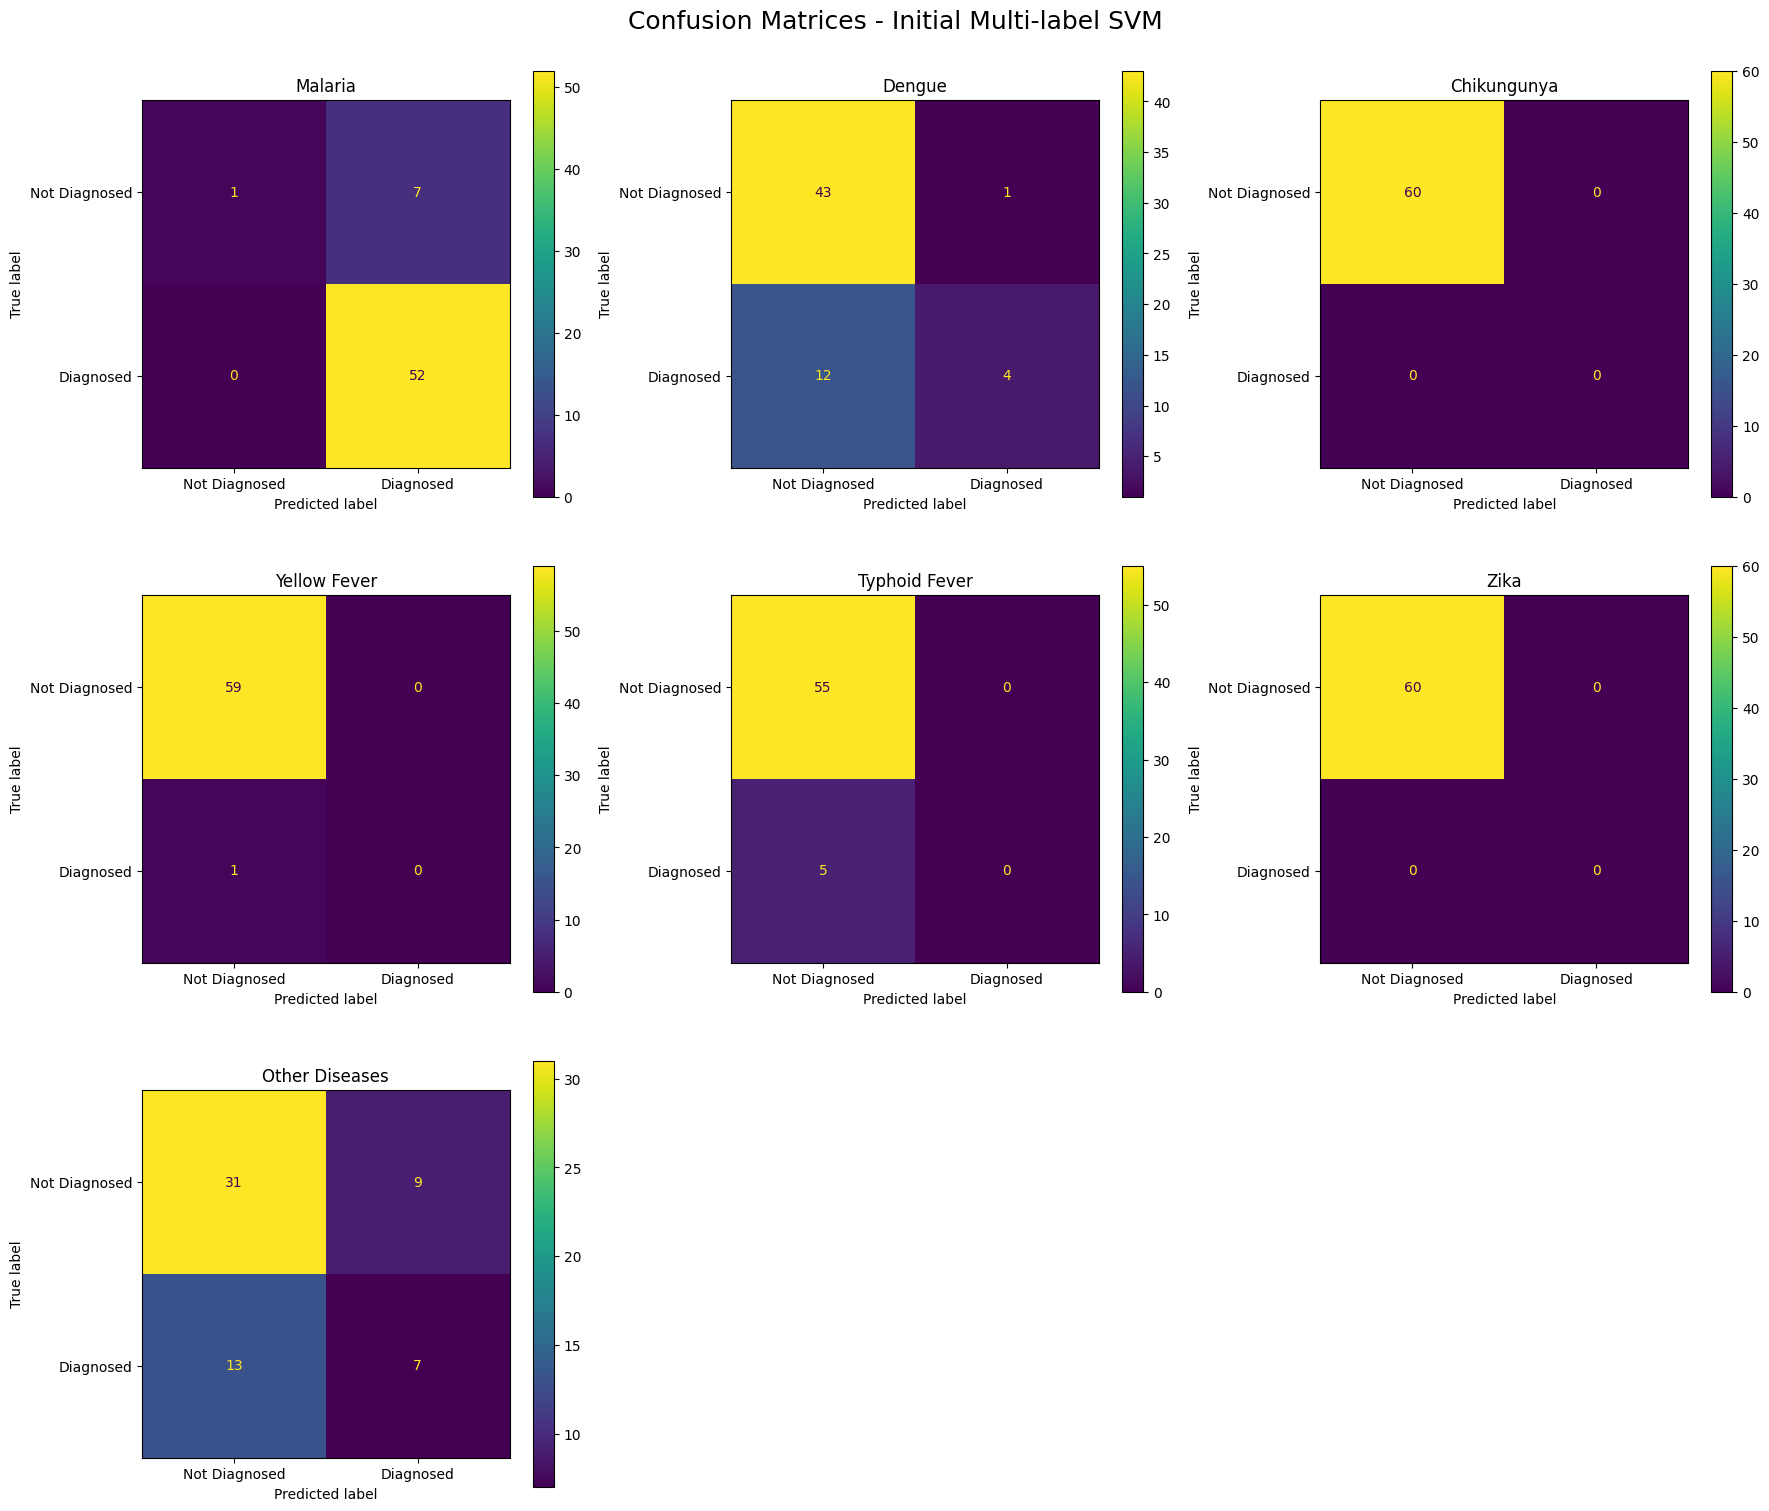


Confusion Matrices for Tuned Multi-label SVM Model:


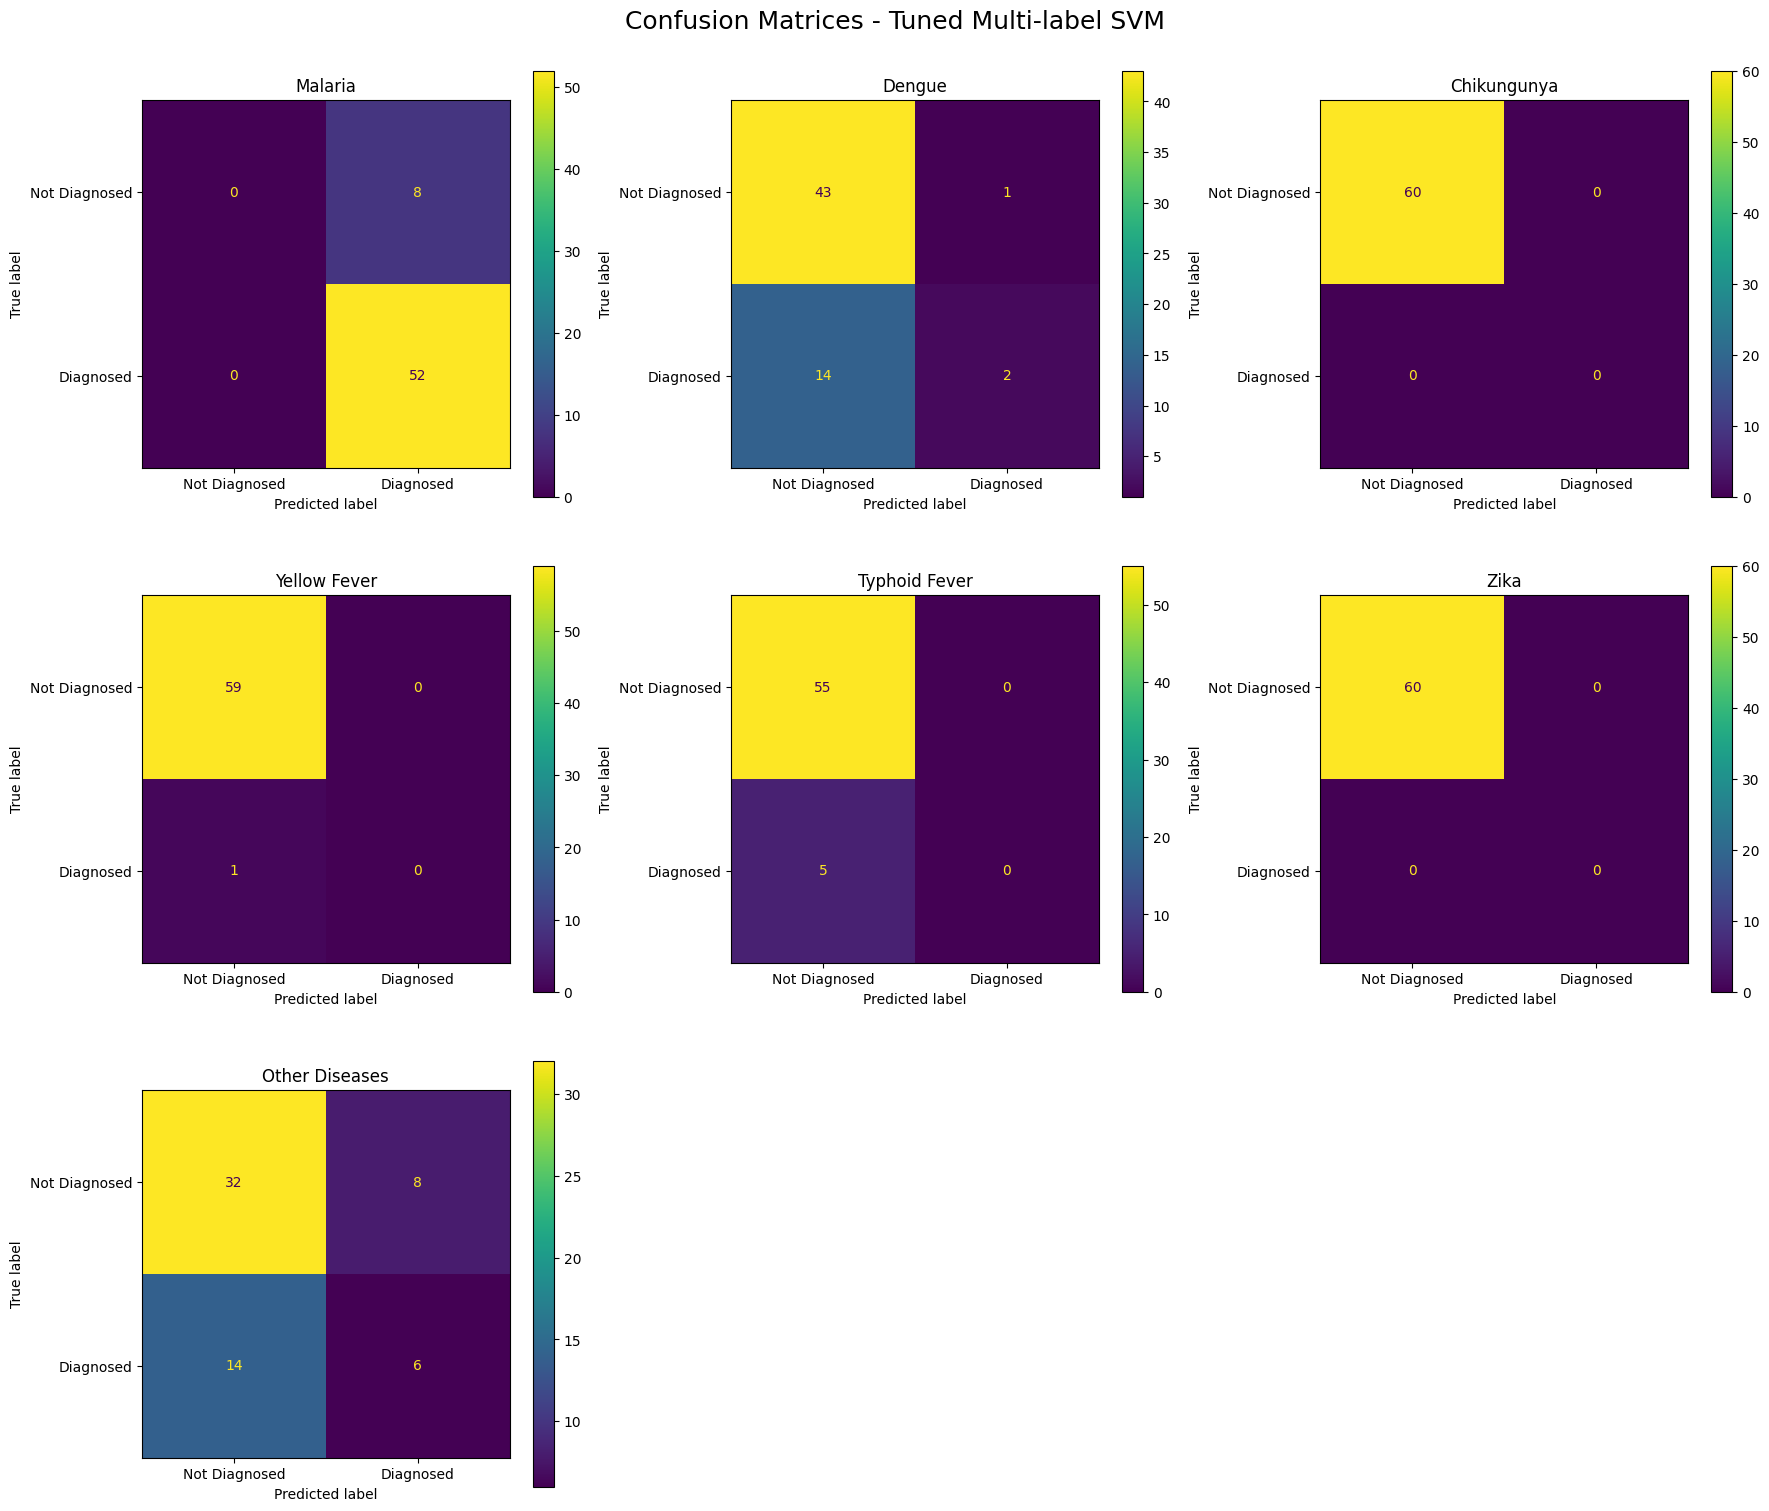

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import multilabel_confusion_matrix
import numpy as np

# Get the list of disease names
disease_names = y_test_multi_filled.columns

# Calculate multi-label confusion matrices for both initial and tuned models
mcm_initial = multilabel_confusion_matrix(y_test_multi_filled, y_pred_multi_initial_filled)
mcm_tuned = multilabel_confusion_matrix(y_test_multi_filled, y_pred_multi_tuned_filled)

# Plot confusion matrices for each disease (Initial Model)
print("Confusion Matrices for Initial Multi-label SVM Model:")
n_classes = len(disease_names)
n_cols_cm = 3 # Adjust as needed
n_rows_cm = (n_classes + n_cols_cm - 1) // n_cols_cm
plt.figure(figsize=(6 * n_cols_cm, 5 * n_rows_cm))

for i, disease in enumerate(disease_names):
    plt.subplot(n_rows_cm, n_cols_cm, i + 1)
    disp = ConfusionMatrixDisplay(confusion_matrix=mcm_initial[i], display_labels=['Not Diagnosed', 'Diagnosed'])
    disp.plot(ax=plt.gca())
    plt.title(f'{disease.replace("Diagnosed: ", "")}')

plt.tight_layout()
plt.suptitle('Confusion Matrices - Initial Multi-label SVM', fontsize=18, y=1.02)
plt.show()

# Plot confusion matrices for each disease (Tuned Model)
print("\nConfusion Matrices for Tuned Multi-label SVM Model:")
plt.figure(figsize=(6 * n_cols_cm, 5 * n_rows_cm))

for i, disease in enumerate(disease_names):
    plt.subplot(n_rows_cm, n_cols_cm, i + 1)
    disp = ConfusionMatrixDisplay(confusion_matrix=mcm_tuned[i], display_labels=['Not Diagnosed', 'Diagnosed'])
    disp.plot(ax=plt.gca())
    plt.title(f'{disease.replace("Diagnosed: ", "")}')

plt.tight_layout()
plt.suptitle('Confusion Matrices - Tuned Multi-label SVM', fontsize=18, y=1.02)
plt.show()

### 15. Finish task

In [ ]:
# Print the accuracies
print(f"Accuracy of the initial binary SVM model: {accuracy_initial:.4f}")
print(f"Accuracy of the tuned binary SVM model: {accuracy_tuned:.4f}")

print(f"\nAccuracy (Subset Accuracy) of the initial multi-label SVM model: {accuracy_multi_initial:.4f}")
print(f"Accuracy (Subset Accuracy) of the tuned multi-label SVM model: {accuracy_multi_tuned:.4f}")

# Print the goal and explanation of the whole SVM model
print("\n--- SVM Model Goal and Explanation ---")
print("\nGoal:")
print("The goal of this SVM model is to classify patients based on their symptoms and other information to determine if they have a vector-borne disease (Binary Classification) and, if so, which specific vector-borne disease(s) they have (Multi-label Classification). This could potentially aid in faster diagnosis and treatment.")

print("\nExplanation:")
print("Support Vector Machines (SVMs) are a powerful type of supervised learning algorithm used for both classification and regression tasks. In classification, SVMs work by finding the optimal hyperplane that best separates the different classes in the feature space. The hyperplane is chosen such that the margin (the distance between the hyperplane and the nearest data points from each class, called support vectors) is maximized. This maximum margin classifier tends to generalize well to unseen data.")
print("\nIn this notebook, we applied SVMs in two ways:")
print("\n1. Binary Classification:")
print("   An initial SVM model was trained to classify whether a patient has *any* vector-borne disease or not. This simplified the problem to two classes ('Has Disease' vs. 'No Disease'). Hyperparameter tuning was performed using GridSearchCV to find the optimal parameters (C and gamma) for the SVM kernel (linear or RBF) to improve performance.")
print("\n2. Multi-label Classification:")
print("   Since a patient can be diagnosed with multiple vector-borne diseases simultaneously, this is inherently a multi-label classification problem. We used the OneVsRest (OvR) strategy. With OvR, a separate binary SVM classifier is trained for each disease. For example, one classifier is trained to distinguish 'Malaria' from 'Not Malaria', another for 'Dengue' from 'Not Dengue', and so on. When making predictions, each individual classifier makes a prediction, and the final prediction is a set of labels (diseases) for which the corresponding classifiers predicted 'Diagnosed'. Similar to the binary case, hyperparameter tuning was applied to the underlying SVM estimators within the OneVsRest framework.")
print("\nOverall, the SVM models were trained on scaled features to ensure that different features contributed equally to the decision-making process. The performance of both the initial and tuned models was evaluated using relevant metrics (accuracy, classification report, confusion matrix for binary classification, and multi-label metrics like exact match ratio, Hamming loss, F1-scores, precision, and recall for multi-label classification). The multi-label confusion matrices provided insights into the model's performance for each specific disease.")


Accuracy of the initial binary SVM model: 0.9667
Accuracy of the tuned binary SVM model: 0.9667

Accuracy (Subset Accuracy) of the initial multi-label SVM model: 0.4333
Accuracy (Subset Accuracy) of the tuned multi-label SVM model: 0.4333

--- SVM Model Goal and Explanation ---

Goal:
The goal of this SVM model is to classify patients based on their symptoms and other information to determine if they have a vector-borne disease (Binary Classification) and, if so, which specific vector-borne disease(s) they have (Multi-label Classification). This could potentially aid in faster diagnosis and treatment.

Explanation:
Support Vector Machines (SVMs) are a powerful type of supervised learning algorithm used for both classification and regression tasks. In classification, SVMs work by finding the optimal hyperplane that best separates the different classes in the feature space. The hyperplane is chosen such that the margin (the distance between the hyperplane and the nearest data points from

Confusion Matrices for Initial Multi-label SVM Model:


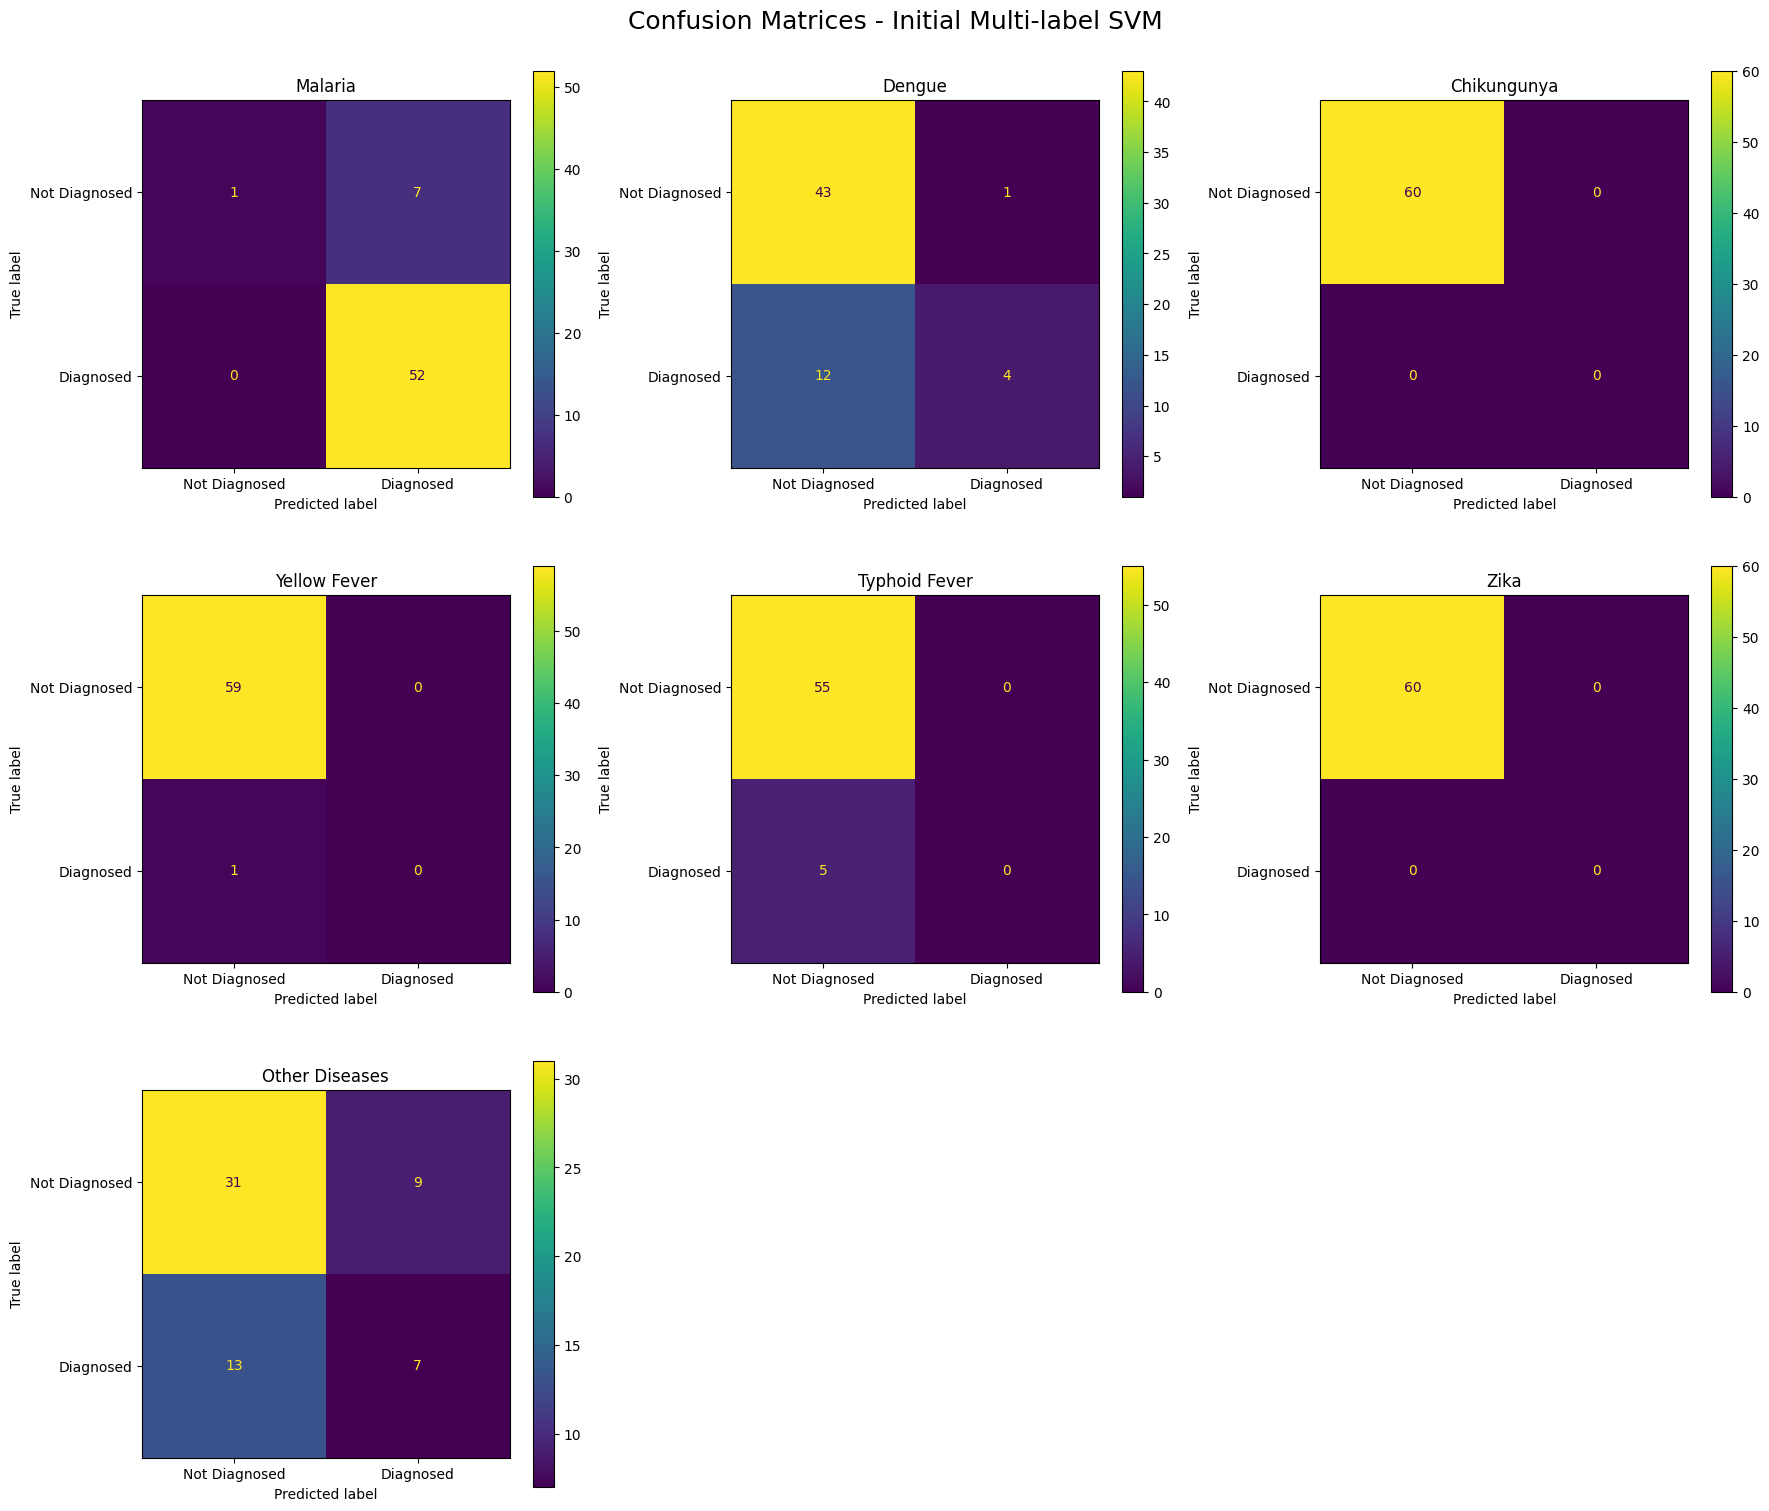


Confusion Matrices for Tuned Multi-label SVM Model:


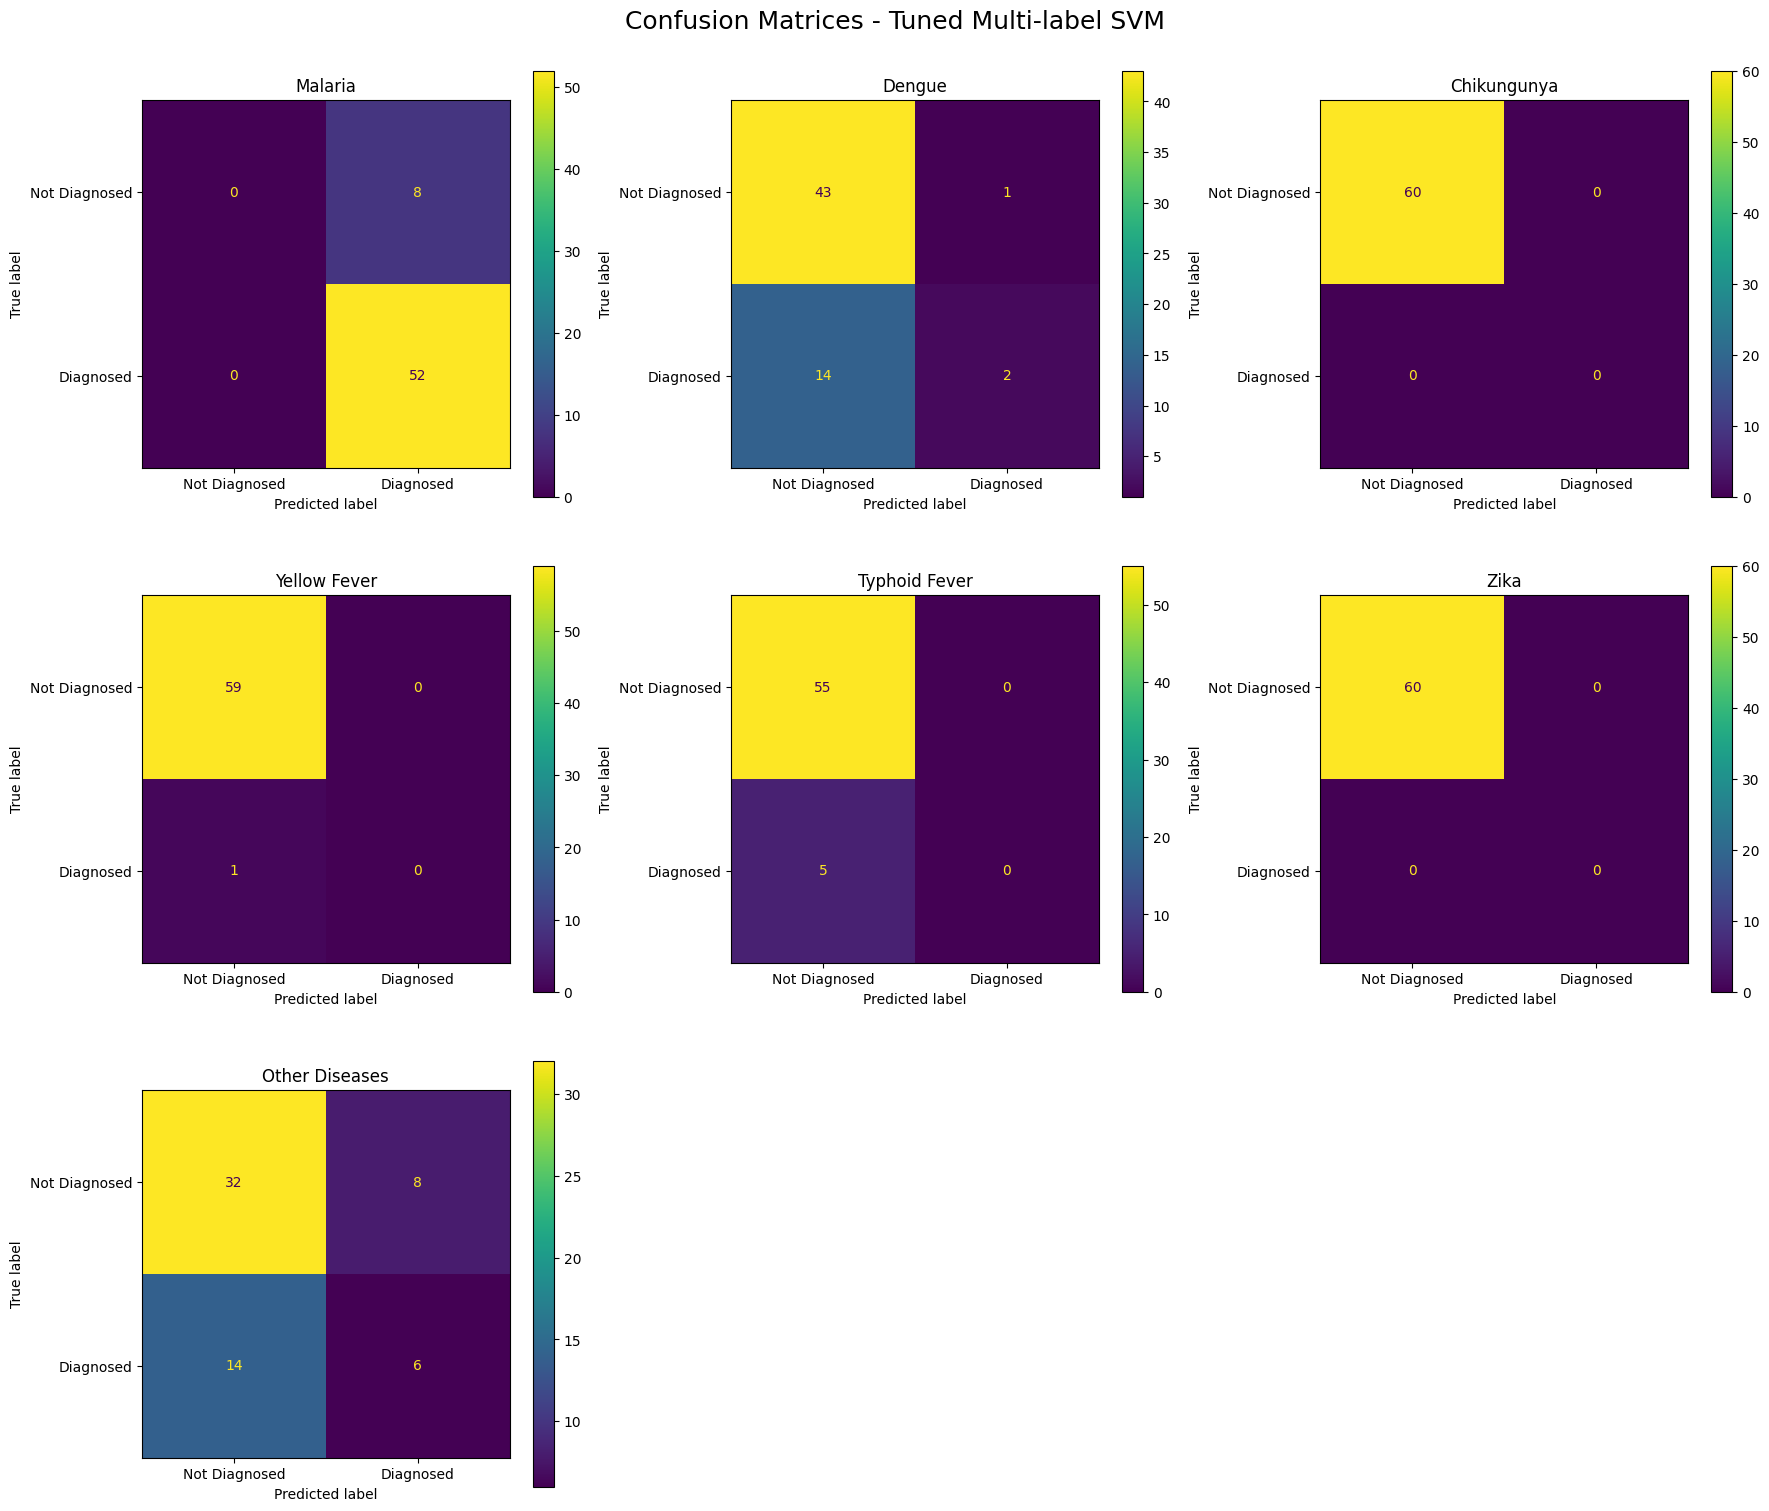

Accuracy of the initial binary SVM model: 0.9667
Accuracy of the tuned binary SVM model: 0.9667

Accuracy (Subset Accuracy) of the initial multi-label SVM model: 0.4333
Accuracy (Subset Accuracy) of the tuned multi-label SVM model: 0.4333

--- SVM Model Goal and Explanation ---

Goal:
The goal of this SVM model is to classify patients based on their symptoms and other information to determine if they have a vector-borne disease (Binary Classification) and, if so, which specific vector-borne disease(s) they have (Multi-label Classification). This could potentially aid in faster diagnosis and treatment.

Explanation:
Support Vector Machines (SVMs) are a powerful type of supervised learning algorithm used for both classification and regression tasks. In classification, SVMs work by finding the optimal hyperplane that best separates the different classes in the feature space. The hyperplane is chosen such that the margin (the distance between the hyperplane and the nearest data points from

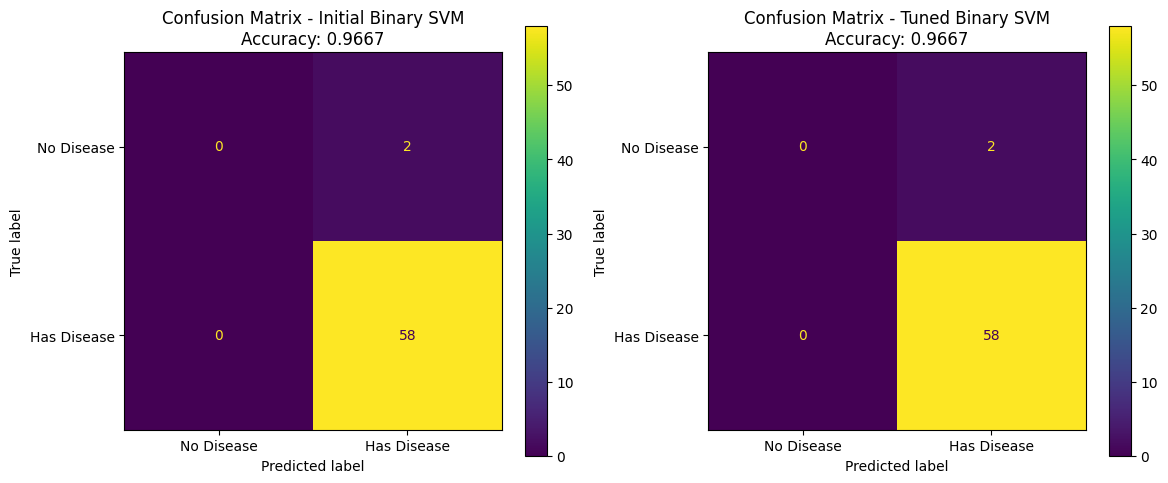


Multi-label SVM Metrics Comparison:


,Metric,Initial Model,Tuned Model
0,Exact Match Ratio,0.4333,0.4333
1,Hamming Loss,0.1143,0.1214
2,Accuracy (Subset),0.4333,0.4333
3,F1-Micro,0.7241,0.7018
4,F1-Macro,0.2438,0.2131
5,F1-Weighted,0.6659,0.6246
6,Precision-Micro,0.7875,0.7792
7,Precision-Macro,0.3027,0.2803
8,Precision-Weighted,0.7168,0.6841
9,Recall-Micro,0.6702,0.6383


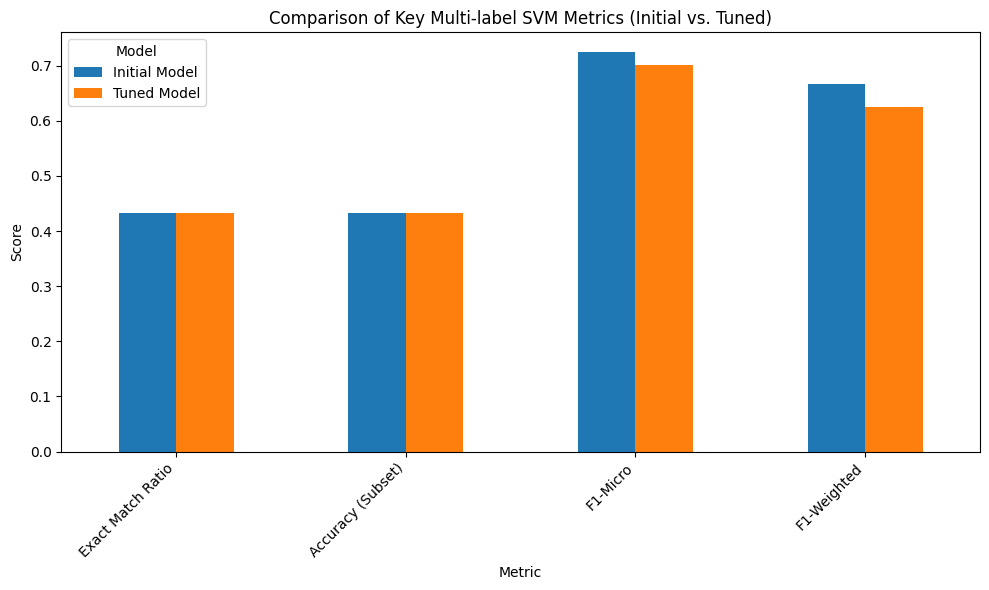

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
# ### 14. Visualize confusion matrices (Multi-label SVM)

# Get the list of disease names
disease_names = y_test_multi_filled.columns

# Calculate multi-label confusion matrices for both initial and tuned models
mcm_initial = multilabel_confusion_matrix(y_test_multi_filled, y_pred_multi_initial_filled)
mcm_tuned = multilabel_confusion_matrix(y_test_multi_filled, y_pred_multi_tuned_filled)

# Plot confusion matrices for each disease (Initial Model)
print("Confusion Matrices for Initial Multi-label SVM Model:")
n_classes = len(disease_names)
n_cols_cm = 3 # Adjust as needed
n_rows_cm = (n_classes + n_cols_cm - 1) // n_cols_cm
plt.figure(figsize=(6 * n_cols_cm, 5 * n_rows_cm))

for i, disease in enumerate(disease_names):
    plt.subplot(n_rows_cm, n_cols_cm, i + 1)
    disp = ConfusionMatrixDisplay(confusion_matrix=mcm_initial[i], display_labels=['Not Diagnosed', 'Diagnosed'])
    disp.plot(ax=plt.gca())
    plt.title(f'{disease.replace("Diagnosed: ", "")}')

plt.tight_layout()
plt.suptitle('Confusion Matrices - Initial Multi-label SVM', fontsize=18, y=1.02)
plt.show()

# Plot confusion matrices for each disease (Tuned Model)
print("\nConfusion Matrices for Tuned Multi-label SVM Model:")
plt.figure(figsize=(6 * n_cols_cm, 5 * n_rows_cm))

for i, disease in enumerate(disease_names):
    plt.subplot(n_rows_cm, n_cols_cm, i + 1)
    disp = ConfusionMatrixDisplay(confusion_matrix=mcm_tuned[i], display_labels=['Not Diagnosed', 'Diagnosed'])
    disp.plot(ax=plt.gca())
    plt.title(f'{disease.replace("Diagnosed: ", "")}')

plt.tight_layout()
plt.suptitle('Confusion Matrices - Tuned Multi-label SVM', fontsize=18, y=1.02)
plt.show()
# ### 15. Finish task
# Print the accuracies
print(f"Accuracy of the initial binary SVM model: {accuracy_initial:.4f}")
print(f"Accuracy of the tuned binary SVM model: {accuracy_tuned:.4f}")

print(f"\nAccuracy (Subset Accuracy) of the initial multi-label SVM model: {accuracy_multi_initial:.4f}")
print(f"Accuracy (Subset Accuracy) of the tuned multi-label SVM model: {accuracy_multi_tuned:.4f}")

# Print the goal and explanation of the whole SVM model
print("\n--- SVM Model Goal and Explanation ---")
print("\nGoal:")
print("The goal of this SVM model is to classify patients based on their symptoms and other information to determine if they have a vector-borne disease (Binary Classification) and, if so, which specific vector-borne disease(s) they have (Multi-label Classification). This could potentially aid in faster diagnosis and treatment.")

print("\nExplanation:")
print("Support Vector Machines (SVMs) are a powerful type of supervised learning algorithm used for both classification and regression tasks. In classification, SVMs work by finding the optimal hyperplane that best separates the different classes in the feature space. The hyperplane is chosen such that the margin (the distance between the hyperplane and the nearest data points from each class, called support vectors) is maximized. This maximum margin classifier tends to generalize well to unseen data.")
print("\nIn this notebook, we applied SVMs in two ways:")
print("\n1. Binary Classification:")
print("   An initial SVM model was trained to classify whether a patient has *any* vector-borne disease or not. This simplified the problem to two classes ('Has Disease' vs. 'No Disease'). Hyperparameter tuning was performed using GridSearchCV to find the optimal parameters (C and gamma) for the SVM kernel (linear or RBF) to improve performance.")
print("\n2. Multi-label Classification:")
print("   Since a patient can be diagnosed with multiple vector-borne diseases simultaneously, this is inherently a multi-label classification problem. We used the OneVsRest (OvR) strategy. With OvR, a separate binary SVM classifier is trained for each disease. For example, one classifier is trained to distinguish 'Malaria' from 'Not Malaria', another for 'Dengue' from 'Not Dengue', and so on. When making predictions, each individual classifier makes a prediction, and the final prediction is a set of labels (diseases) for which the corresponding classifiers predicted 'Diagnosed'. Similar to the binary case, hyperparameter tuning was applied to the underlying SVM estimators within the OneVsRest framework.")
print("\nOverall, the SVM models were trained on scaled features to ensure that different features contributed equally to the decision-making process. The performance of both the initial and tuned models was evaluated using relevant metrics (accuracy, classification report, confusion matrix for binary classification, and multi-label metrics like exact match ratio, Hamming loss, F1-scores, precision, and recall for multi-label classification). The multi-label confusion matrices provided insights into the model's performance for each specific disease.")



# Add plots to visualize the results of the SVM models

# Visualize the results of the binary SVM model (initial and tuned) side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Confusion Matrix for Initial Binary SVM
cm_initial = confusion_matrix(y_test, y_pred_initial)
disp_initial = ConfusionMatrixDisplay(confusion_matrix=cm_initial, display_labels=['No Disease', 'Has Disease'])
disp_initial.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix - Initial Binary SVM\nAccuracy: {accuracy_initial:.4f}')

# Plot Confusion Matrix for Tuned Binary SVM
cm_tuned = confusion_matrix(y_test, y_pred_tuned) # Corrected typo here
disp_tuned = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=['No Disease', 'Has Disease'])
disp_tuned.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix - Tuned Binary SVM\nAccuracy: {accuracy_tuned:.4f}')

plt.tight_layout()
plt.show()

# Visualize a summary of multi-label metrics for initial and tuned models
metrics_summary = pd.DataFrame({
    'Metric': ['Exact Match Ratio', 'Hamming Loss', 'Accuracy (Subset)',
               'F1-Micro', 'F1-Macro', 'F1-Weighted',
               'Precision-Micro', 'Precision-Macro', 'Precision-Weighted',
               'Recall-Micro', 'Recall-Macro', 'Recall-Weighted'],
    'Initial Model': [exact_match_ratio, hamming_loss_initial, accuracy_multi_initial,
                      f1_multi_initial_micro, f1_multi_initial_macro, f1_multi_initial_weighted,
                      precision_multi_initial_micro, precision_multi_initial_macro, precision_multi_initial_weighted,
                      recall_multi_initial_micro, recall_multi_initial_macro, recall_multi_initial_weighted],
    'Tuned Model': [exact_match_ratio_tuned, hamming_loss_tuned, accuracy_multi_tuned,
                    f1_multi_tuned_micro, f1_multi_tuned_macro, f1_multi_tuned_weighted,
                    precision_multi_tuned_micro, precision_multi_tuned_macro, precision_multi_tuned_weighted,
                    recall_multi_tuned_micro, recall_multi_tuned_macro, recall_multi_tuned_weighted]
})

print("\nMulti-label SVM Metrics Comparison:")
display(metrics_summary.round(4))

# You can also visualize some of these multi-label metrics using bar plots if desired
metrics_to_plot = ['Exact Match Ratio', 'Accuracy (Subset)', 'F1-Micro', 'F1-Weighted']
plt.figure(figsize=(10, 6))
metrics_summary[metrics_summary['Metric'].isin(metrics_to_plot)].set_index('Metric').plot(kind='bar', ax=plt.gca())
plt.title('Comparison of Key Multi-label SVM Metrics (Initial vs. Tuned)')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

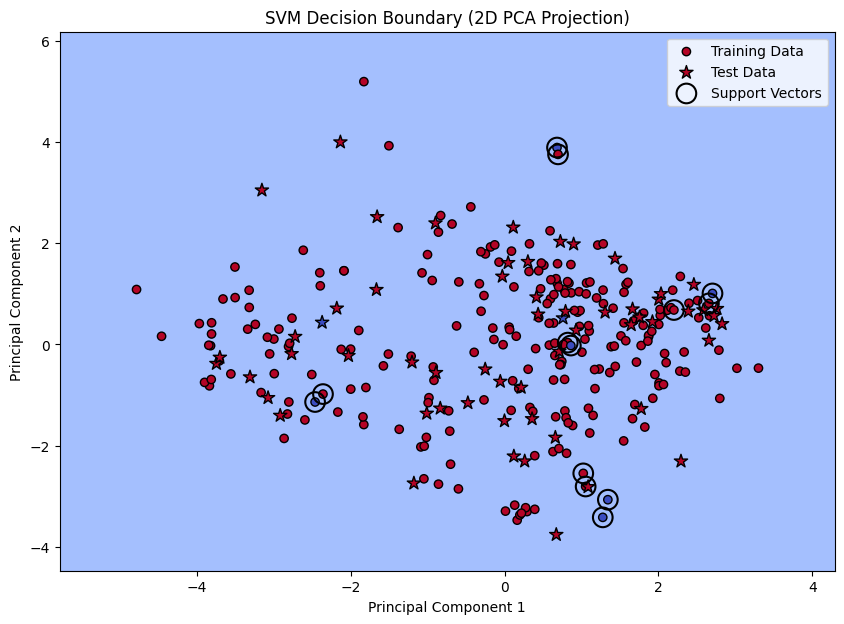

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Reduce dimensions for visualization using PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled_df)
X_test_pca = pca.transform(X_test_scaled_df)

# Train a new SVM model on the 2D PCA data (using the best tuned parameters for binary classification)
svm_model_pca = SVC(C=best_params['C'], gamma=best_params['gamma'], kernel=best_params['kernel'], random_state=42)
svm_model_pca.fit(X_train_pca, y_train)

# Create a meshgrid to plot the decision boundary
h = .02  # step size in the mesh
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict the class for each point in the meshgrid
Z = svm_model_pca.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the decision boundary and the data points
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.8)

# Plot also the training points
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', label='Training Data')
plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap=plt.cm.coolwarm, edgecolors='k', marker='*', s=100, label='Test Data')

# Plot the support vectors
plt.scatter(svm_model_pca.support_vectors_[:, 0], svm_model_pca.support_vectors_[:, 1], s=200,
            facecolors='none', edgecolors='k', linewidths=1.5, label='Support Vectors')


plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('SVM Decision Boundary (2D PCA Projection)')
plt.legend()
plt.show()

### Visualizing SVM Concepts: Kernel Trick, Margin, and Support Vectors

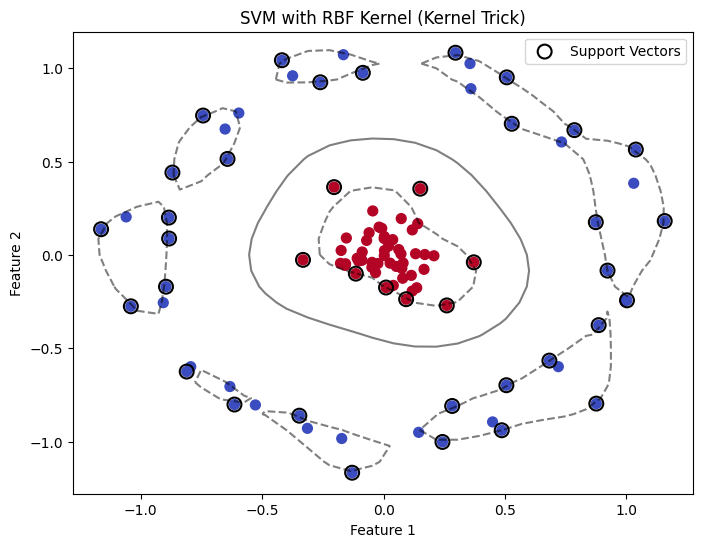

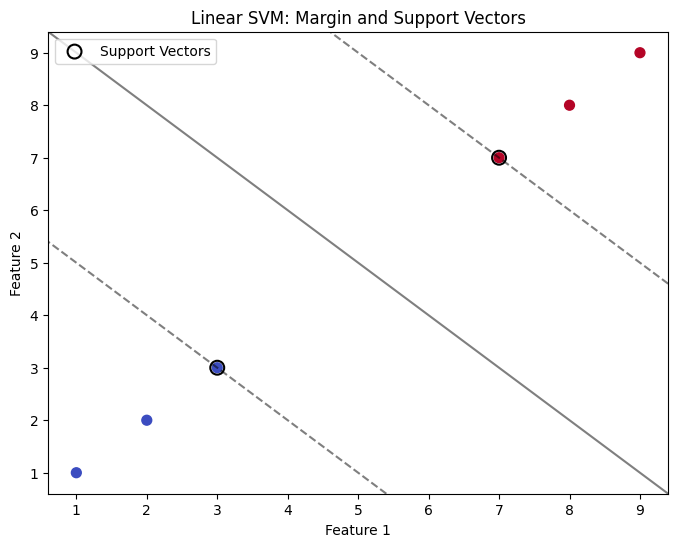

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.datasets import make_circles

# Generate synthetic data for illustrating the kernel trick (non-linear separation)
X_nonlinear, y_nonlinear = make_circles(n_samples=100, factor=.1, noise=.1, random_state=42)

# Train an SVM with an RBF kernel (demonstrating the kernel trick)
clf_nonlinear = svm.SVC(kernel='rbf', gamma=10, C=1)
clf_nonlinear.fit(X_nonlinear, y_nonlinear)

# Plot the non-linear data and the decision boundary
plt.figure(figsize=(8, 6))
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1], c=y_nonlinear, s=50, cmap=plt.cm.coolwarm)

# Plot the decision boundary
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf_nonlinear.decision_function(xy).reshape(XX.shape)

# Plot decision boundary and margins
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])

# Plot support vectors
ax.scatter(clf_nonlinear.support_vectors_[:, 0], clf_nonlinear.support_vectors_[:, 1], s=100,
           facecolors='none', edgecolors='k', linewidths=1.5, label='Support Vectors')

plt.title('SVM with RBF Kernel (Kernel Trick)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

# Generate synthetic data for illustrating the margin and support vectors (linear separation)
X_linear = np.array([[1, 1], [2, 2], [3, 3], [7, 7], [8, 8], [9, 9]])
y_linear = np.array([0, 0, 0, 1, 1, 1])

# Train a linear SVM
clf_linear = svm.SVC(kernel='linear', C=1)
clf_linear.fit(X_linear, y_linear)

# Plot the linearly separable data and the decision boundary, margin, and support vectors
plt.figure(figsize=(8, 6))
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear, s=50, cmap=plt.cm.coolwarm)

# Plot the decision boundary and margins
ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf_linear.decision_function(xy).reshape(XX.shape)

# Plot decision boundary and margins
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])

# Plot support vectors
ax.scatter(clf_linear.support_vectors_[:, 0], clf_linear.support_vectors_[:, 1], s=100,
           facecolors='none', edgecolors='k', linewidths=1.5, label='Support Vectors')

plt.title('Linear SVM: Margin and Support Vectors')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()

In [ ]:
# Define the columns that represent vector-borne diseases
vector_borne_cols = ['Diagnosed: Malaria', 'Diagnosed: Dengue',
                     'Diagnosed: Chikungunya', 'Diagnosed: Yellow Fever',
                     'Diagnosed: Zika']

# Create the binary target variable: 1 if any of the vector_borne_cols is 1, 0 otherwise
df['is_vector_borne'] = df[vector_borne_cols].max(axis=1)

# Display the distribution of the new target variable
print("Distribution of the new binary target variable ('is_vector_borne'):")
display(df['is_vector_borne'].value_counts())

# Display the head of the DataFrame with the new column
display(df.head())

Distribution of the new binary target variable ('is_vector_borne'):


,count
is_vector_borne,
1.0,283
0.0,14


,Age,Fever_Level,Respiratory rate (median breaths/min IQR),Pulse rate (mean beats/min ± SD),Retro-orbital pain,Headache,Muscle Pain,Joint Pain,Joint Swelling,Vomiting,...,Diagnosed Diseases,Diagnosed: Malaria,Diagnosed: Dengue,Diagnosed: Chikungunya,Diagnosed: Yellow Fever,Diagnosed: Typhoid Fever,Diagnosed: Zika,Diagnosed: Other Diseases,Has_Vector_Borne_Disease,is_vector_borne
0,18,Severe,26,131,0,1,1,1,0,0,...,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0,1.0,1.0
1,26,Severe,28,38,0,1,1,1,0,1,...,"Malaria, Dengue",1.0,1.0,0.0,0.0,0.0,0.0,0,1.0,1.0
2,25,Severe,22,100,0,1,1,1,0,1,...,"Malaria, Typhoid Fever",1.0,0.0,0.0,0.0,1.0,0.0,0,1.0,1.0
3,3,Moderate,26,88,0,1,0,0,0,1,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0,1.0,1.0
4,8,Moderate,32,109,0,1,1,0,0,1,...,Malaria,1.0,0.0,0.0,0.0,0.0,0.0,0,1.0,1.0


**Summary of Findings:**

*   **Binary Classification:** Both the initial and tuned SVM models achieved high overall accuracy in predicting whether a patient has any vector-borne disease. However, the confusion matrices show that the models struggled to correctly identify patients who do *not* have a vector-borne disease, likely due to the imbalanced nature of the dataset (very few instances of 'No Disease').

*   **Multi-label Classification:** The multi-label SVM model, using a OneVsRest strategy, provides predictions for each specific disease. The evaluation metrics (Exact Match Ratio, Hamming Loss, F1-scores, Precision, and Recall) give a clearer picture of the model's performance across all diseases. The confusion matrices for each disease highlight the individual performance, showing which diseases are easier or harder for the model to predict accurately.

**Further Steps:**

*   **Address Data Imbalance:** The significant class imbalance in the binary classification (and likely in individual diseases in the multi-label case) needs to be addressed. Techniques like oversampling the minority class (e.g., using SMOTE) or undersampling the majority class could improve the model's ability to predict the minority class correctly.
*   **Explore Other Models:** While SVMs were used here, exploring other multi-label classification algorithms (e.g., Classification Chains, Label Powerset, or deep learning models) might yield better results, especially for complex relationships between features and multiple labels.
*   **Feature Importance:** Investigating feature importance could help understand which symptoms or demographic factors are most influential in predicting each disease.
*   **Threshold Tuning:** For multi-label classification, adjusting the prediction threshold for each label independently could improve the F1-score and balance precision and recall based on the specific requirements of the application.
*   **More Data:** Obtaining a larger and more balanced dataset would significantly improve the model's ability to generalize and perform accurately.